<a href="https://colab.research.google.com/github/hycienti/African_Credit_Scoring_ML/blob/main/African_Credit_Scoring_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Africa Credit Scoring Model

### Motivation & Project Background
While studying the robust credit-scoring systems of the United States and the United Kingdom, I began to reflect on how we could establish a similar, highly efficient, fast, and reliable credit-scoring infrastructure back home in Nigeria.

One of my core personal and professional missions has been to foster seamless cross-border payments across Africa. I firmly believe that one of the most powerful levers for increasing overall financial inclusivity across the continent is ensuring reliable, democratized access to credit facilities.

However, upon searching for completely African-driven datasets to build, validate, and test this credit-scoring vision, I discovered a significant data gap. Fortunately, I came across a competition hosted by **Zindi Africa** addressing this precise challenge and subsequently downloaded their dataset.

### Data Source
The dataset utilized for this machine learning project is sourced from the [African Credit Scoring Challenge](https://zindi.world/competitions/african-credit-scoring-challenge) hosted on Zindi.

## Project Objective & Notebook Roadmap

**Problem framing.** For every loan, predict at disbursement time whether it will default (`target = 1`). This is a **binary classification** problem with a severe class imbalance (≈1.8% defaults), and the model's output is used as a **risk score** that a lender ranks and thresholds.

**Evaluation design (why it matters here).**
- The Zindi `Test.csv` has **no labels**, so all honest evaluation happens on data carved out of `Train.csv`.
- The same customer appears in many loans. A random row split would put a borrower's loans in both train and validation, letting models memorise the borrower instead of learning risk. All splits here are therefore **grouped by `customer_id`** (and stratified on the target).
- Three disjoint splits: **train** (fit + cross-validated tuning), **validation** (early stopping, decision threshold, model selection), and **holdout** (touched once, for the final ML-vs-DL comparison).
- **Primary metric: PR-AUC (average precision).** With 1.8% positives, accuracy is meaningless (predicting "never defaults" scores ~98%) and ROC-AUC can look flattering. PR-AUC directly measures how well defaults are ranked above good loans; its random baseline equals the default rate. ROC-AUC, precision, recall, F1 (at a validation-tuned threshold) and confusion matrices are reported alongside.

**Roadmap**
1. Setup & reproducibility
2. Load & inspect the data
3. Exploratory data analysis
4. Feature engineering & leakage-safe preprocessing
5. **Part 1 — Traditional Machine Learning (Scikit-Learn):** Logistic Regression, Random Forest, SVM — baselines, hyperparameter search, learning curves, feature importance
6. **Part 2 — Deep Learning (TensorFlow / Keras):** `tf.data` pipelines, Sequential and Functional (wide & deep with embeddings) architectures, imbalance strategies, hyperparameter sweep
7. ML vs DL comparison on the holdout set (with bootstrap confidence intervals)
8. Error analysis & an unseen-lender robustness test (proxy for the new country in the test set)
9. Dataset limitations & conclusions
10. Zindi submission & TensorBoard dashboard

Every experiment is tracked in **TensorBoard** under a descriptive run name.

## 1. Setup & Reproducibility

In [2]:
# ── Imports ──────────────────────────────────────────────────────────────────
import os, io, re, random, datetime, warnings
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')   # hide TensorFlow C++ info logs
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import loguniform, randint, uniform

import sklearn
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.model_selection import StratifiedGroupKFold, RandomizedSearchCV, learning_curve
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.kernel_approximation import Nystroem
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score,
                             recall_score, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, precision_recall_curve, classification_report)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from tensorboard.plugins.hparams import api as hp

warnings.filterwarnings('ignore')
tf.get_logger().setLevel('ERROR')                   # hide tf.function retracing notices
pd.set_option('display.max_columns', 60)
sns.set_theme(style='whitegrid')

# ── Reproducibility ──────────────────────────────────────────────────────────
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)          # seeds Python, NumPy and TensorFlow together
# tf.config.experimental.enable_op_determinism()  # bit-exact GPU runs (slower); optional

# QUICK_RUN=1 shrinks searches/epochs for a fast smoke test. Leave it off for the real run.
QUICK_RUN = os.environ.get('QUICK_RUN', '0') == '1'

# ── Paths (Google Drive on Colab, local folder elsewhere) ────────────────────
try:
    from google.colab import drive
    drive.mount('/content/drive')
    persistent_project_dir = '/content/drive/My Drive/Colab Notebooks/African_credit_scoring_ml/'
except ImportError:
    persistent_project_dir = os.environ.get('CREDIT_PROJECT_DIR', './')
os.makedirs(persistent_project_dir, exist_ok=True)

print(f"Project directory : {persistent_project_dir}")
print(f"Versions          : numpy {np.__version__} | pandas {pd.__version__} | scikit-learn {sklearn.__version__} "
      f"| tensorflow {tf.__version__} | keras {keras.__version__}")
print(f"GPU available     : {bool(tf.config.list_physical_devices('GPU'))} | QUICK_RUN={QUICK_RUN}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project directory : /content/drive/My Drive/Colab Notebooks/African_credit_scoring_ml/
Versions          : numpy 2.1.3 | pandas 2.2.3 | scikit-learn 1.6.1 | tensorflow 2.21.0 | keras 3.13.2
GPU available     : True | QUICK_RUN=False


### Experiment tracking with TensorBoard

Every experiment, from both paradigms, is written to TensorBoard under the naming convention

`<Paradigm>_<NN>_<Model>_<stage>__<key hyperparameters>`

for example `ML_05_RandomForest_tuned__n-412_depth-14_leaf-9_mf-sqrt_cw-balanced_subsample` or `DL_04_WideDeep_embeddings_classweights__u-128-64_do-0.3_l2-0.0001_loss-bce_cw-balanced_lr-0.001`.

What gets logged:
- **HParams tab:** the hyperparameters and final metrics of every run, so runs can be sorted and filtered side by side (including every candidate tried by the scikit-learn hyperparameter searches).
- **Scalars tab:** validation metrics, scikit-learn learning curves (x-axis = training-set size), and per-epoch Keras curves (loss, PR-AUC, ROC-AUC, precision, recall, learning rate).
- **Images tab:** confusion matrix, ROC curve and precision-recall curve for each evaluated model.
- **Histograms / Distributions tabs:** Keras weight distributions per epoch.

Each notebook session writes into its own `session_<timestamp>` folder, so reruns never overwrite earlier experiments.

In [3]:
TB_ROOT = os.path.join(persistent_project_dir, 'tensorboard_logs')
SESSION = datetime.datetime.now().strftime('%Y%m%d-%H%M%S')
LOG_DIR = os.path.join(TB_ROOT, f'session_{SESSION}')
os.makedirs(LOG_DIR, exist_ok=True)

RESULTS = []   # one row per evaluated experiment (validation metrics)
MODELS = {}    # run name -> fitted model + how to feed it


def _fmt(v):
    """Compact, filesystem-safe rendering of a hyperparameter value for run names."""
    if isinstance(v, Nystroem):
        return f'rbfNystroem{v.n_components}'
    if isinstance(v, str) and v == 'passthrough':
        return 'linear'
    if v is None or v is np.ma.masked or (isinstance(v, float) and np.isnan(v)):
        return 'none'
    if isinstance(v, (tuple, list)):
        return '-'.join(_fmt(x) for x in v)
    if isinstance(v, (float, np.floating)):
        return f'{v:.3g}'
    return str(v)


def run_name(paradigm, idx, model, **params):
    """e.g. run_name('ML', 5, 'RandomForest_tuned', depth=14) -> 'ML_05_RandomForest_tuned__depth-14'."""
    tail = '_'.join(f'{k}-{_fmt(v)}' for k, v in params.items())
    name = f'{paradigm}_{idx:02d}_{model}' + (f'__{tail}' if tail else '')
    return re.sub(r'[^A-Za-z0-9_.\-]', '', name)


def _hparam_value(v):
    """HParams only accepts bool/int/float/str."""
    if isinstance(v, (bool, np.bool_)):
        return bool(v)
    if isinstance(v, (int, np.integer)):
        return int(v)
    if isinstance(v, (float, np.floating)) and not np.isnan(v):
        return float(v)
    return _fmt(v)


def fig_to_tensor(fig):
    buf = io.BytesIO()
    fig.savefig(buf, format='png', dpi=90, bbox_inches='tight')
    return tf.expand_dims(tf.image.decode_png(buf.getvalue(), channels=4), 0)


def log_run(name, hparams=None, metrics=None, figures=None, step=0):
    """Write hyperparameters, scalar metrics and figures for one run to TensorBoard."""
    with tf.summary.create_file_writer(os.path.join(LOG_DIR, name)).as_default():
        if hparams:
            hp.hparams({k: _hparam_value(v) for k, v in hparams.items()}, trial_id=name)
        for k, v in (metrics or {}).items():
            tf.summary.scalar(k, float(v), step=step)
        for k, fig in (figures or {}).items():
            tf.summary.image(k, fig_to_tensor(fig), step=step)


# ── Metrics ──────────────────────────────────────────────────────────────────
def get_scores(model, X):
    """Continuous risk score: probability if the model has one, otherwise the SVM margin.
    Ranking metrics (ROC-AUC, PR-AUC) only need an ordering, so a margin is as valid as a probability."""
    if hasattr(model, 'predict_proba'):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)


def best_f1_threshold(y_true, scores):
    """Decision threshold that maximises F1 on the given (validation) data."""
    p, r, t = precision_recall_curve(y_true, scores)
    f1 = 2 * p * r / np.clip(p + r, 1e-12, None)
    return float(t[np.nanargmax(f1[:-1])])


def compute_metrics(y_true, scores, threshold):
    y_pred = (scores >= threshold).astype(int)
    return {'pr_auc': average_precision_score(y_true, scores),
            'roc_auc': roc_auc_score(y_true, scores),
            'f1': f1_score(y_true, y_pred, zero_division=0),
            'precision': precision_score(y_true, y_pred, zero_division=0),
            'recall': recall_score(y_true, y_pred, zero_division=0),
            'threshold': threshold}


def plot_evaluation(title, y_true, scores, threshold, split):
    """Confusion matrix (at threshold) + ROC + precision-recall curves in one figure."""
    y_pred = (scores >= threshold).astype(int)
    fig, axs = plt.subplots(1, 3, figsize=(17, 4.6))
    ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred), display_labels=['repaid', 'default']).plot(
        ax=axs[0], cmap='Blues', colorbar=False, values_format='d')
    axs[0].set_title(f'Confusion matrix ({split}, threshold={threshold:.3g})'); axs[0].grid(False)
    fpr, tpr, _ = roc_curve(y_true, scores)
    axs[1].plot(fpr, tpr, lw=2, label=f'ROC-AUC = {roc_auc_score(y_true, scores):.3f}')
    axs[1].plot([0, 1], [0, 1], 'k--', lw=1, label='random')
    axs[1].set(xlabel='False positive rate', ylabel='True positive rate (recall)', title='ROC curve')
    axs[1].legend(loc='lower right')
    p, r, _ = precision_recall_curve(y_true, scores)
    axs[2].plot(r, p, lw=2, label=f'PR-AUC = {average_precision_score(y_true, scores):.3f}')
    axs[2].axhline(y_true.mean(), color='k', ls='--', lw=1, label=f'random = {y_true.mean():.3f}')
    axs[2].set(xlabel='Recall', ylabel='Precision', title='Precision-recall curve')
    axs[2].legend(loc='upper right')
    fig.suptitle(title, fontsize=10)
    fig.tight_layout()
    return fig


def record_experiment(name, family, hparams, y_true, scores, show=True):
    """Tune the threshold on validation, compute metrics, log to TensorBoard, store in RESULTS."""
    thr = best_f1_threshold(y_true, scores)
    m = compute_metrics(y_true, scores, thr)
    fig = plot_evaluation(name, y_true, scores, thr, split='validation')
    log_run(name, {'family': family, **hparams}, {f'val/{k}': v for k, v in m.items()},
            figures={'validation_evaluation': fig})
    plt.show() if show else plt.close(fig)
    RESULTS.append({'run': name, 'paradigm': name.split('_')[0], 'family': family,
                    **{f'val_{k}': v for k, v in m.items()}})
    print(f"{name}\n  val PR-AUC={m['pr_auc']:.4f} | ROC-AUC={m['roc_auc']:.4f} | F1={m['f1']:.4f} "
          f"| precision={m['precision']:.4f} | recall={m['recall']:.4f} @ threshold={thr:.4g}")
    return m

print(f'TensorBoard logs for this session -> {LOG_DIR}')

TensorBoard logs for this session -> /content/drive/My Drive/Colab Notebooks/African_credit_scoring_ml/tensorboard_logs/session_20261018-183046


## 2. Load & Inspect the Data

In [4]:
train = pd.read_csv(os.path.join(persistent_project_dir, 'Train.csv'))
test = pd.read_csv(os.path.join(persistent_project_dir, 'Test.csv'))
display('Train', train.head(), train.shape, 'Test', test.head(), test.shape)

'Train'

,ID,customer_id,country_id,tbl_loan_id,lender_id,loan_type,Total_Amount,Total_Amount_to_Repay,disbursement_date,due_date,duration,New_versus_Repeat,Amount_Funded_By_Lender,Lender_portion_Funded,Lender_portion_to_be_repaid,target
0,ID_266671248032267278,266671,Kenya,248032,267278,Type_1,8448.0,8448.0,2022-08-30,2022-09-06,7,Repeat Loan,120.85,0.014305,121.0,0
1,ID_248919228515267278,248919,Kenya,228515,267278,Type_1,25895.0,25979.0,2022-07-30,2022-08-06,7,Repeat Loan,7768.50,0.300000,7794.0,0
2,ID_308486370501251804,308486,Kenya,370501,251804,Type_7,6900.0,7142.0,2024-09-06,2024-09-13,7,Repeat Loan,1380.00,0.200000,1428.0,0
3,ID_266004285009267278,266004,Kenya,285009,267278,Type_1,8958.0,9233.0,2022-10-20,2022-10-27,7,Repeat Loan,2687.40,0.300000,2770.0,0
4,ID_253803305312267278,253803,Kenya,305312,267278,Type_1,4564.0,4728.0,2022-11-28,2022-12-05,7,Repeat Loan,1369.20,0.300000,1418.0,0


(68654, 16)

'Test'

,ID,customer_id,country_id,tbl_loan_id,lender_id,loan_type,Total_Amount,Total_Amount_to_Repay,disbursement_date,due_date,duration,New_versus_Repeat,Amount_Funded_By_Lender,Lender_portion_Funded,Lender_portion_to_be_repaid
0,ID_269404226088267278,269404,Kenya,226088,267278,Type_1,1919.0,1989.0,2022-07-27,2022-08-03,7,Repeat Loan,575.7,0.300000,597.0
1,ID_255356300042267278,255356,Kenya,300042,267278,Type_1,2138.0,2153.0,2022-11-16,2022-11-23,7,Repeat Loan,0.0,0.000000,0.0
2,ID_257026243764267278,257026,Kenya,243764,267278,Type_1,8254.0,8304.0,2022-08-24,2022-08-31,7,Repeat Loan,207.0,0.025079,208.0
3,ID_264617299409267278,264617,Kenya,299409,267278,Type_1,3379.0,3379.0,2022-11-15,2022-11-22,7,Repeat Loan,1013.7,0.300000,1014.0
4,ID_247613296713267278,247613,Kenya,296713,267278,Type_1,120.0,120.0,2022-11-10,2022-11-17,7,Repeat Loan,36.0,0.300000,36.0


(18594, 15)

In [5]:
train.info()
print(f"\nMissing values  -> train: {train.isna().sum().sum()} | test: {test.isna().sum().sum()}")
print(f"Duplicate IDs   -> train: {train['ID'].duplicated().sum()} | test: {test['ID'].duplicated().sum()}")
print(f"Train/test ID overlap: {len(set(train['ID']) & set(test['ID']))}")
display(pd.DataFrame({'train_unique': train.nunique(), 'test_unique': test.nunique()}))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 68654 entries, 0 to 68653
Data columns (total 16 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           68654 non-null  object 
 1   customer_id                  68654 non-null  int64  
 2   country_id                   68654 non-null  object 
 3   tbl_loan_id                  68654 non-null  int64  
 4   lender_id                    68654 non-null  int64  
 5   loan_type                    68654 non-null  object 
 6   Total_Amount                 68654 non-null  float64
 7   Total_Amount_to_Repay        68654 non-null  float64
 8   disbursement_date            68654 non-null  object 
 9   due_date                     68654 non-null  object 
 10  duration                     68654 non-null  int64  
 11  New_versus_Repeat            68654 non-null  object 
 12  Amount_Funded_By_Lender      68654 non-null  float64
 13  Lender_portion_F

,train_unique,test_unique
Amount_Funded_By_Lender,23391,9704.0
ID,68654,18594.0
Lender_portion_Funded,12844,3880.0
Lender_portion_to_be_repaid,9791,6782.0
New_versus_Repeat,2,2.0
Total_Amount,19076,9372.0
Total_Amount_to_Repay,21920,10963.0
country_id,1,2.0
customer_id,6540,4962.0
disbursement_date,768,656.0


**Column roles**

| Group | Columns | Treatment |
|---|---|---|
| Identifiers | `ID`, `customer_id`, `tbl_loan_id` | Never used as numeric features (arbitrary numbers). `customer_id` is used for grouped splitting and borrower-history features. |
| Categorical | `country_id`, `lender_id`, `loan_type`, `New_versus_Repeat` | Encoded (one-hot for scikit-learn, learned embeddings for the wide & deep network). |
| Loan terms | `Total_Amount`, `Total_Amount_to_Repay`, `duration`, `Amount_Funded_By_Lender`, `Lender_portion_Funded`, `Lender_portion_to_be_repaid` | Skewed amounts are log-transformed; pricing ratios engineered. |
| Dates | `disbursement_date`, `due_date` | Calendar features and loan term; the raw year is deliberately excluded (see feature engineering). |
| Target | `target` | 1 = defaulted. |

There are no missing values, so preprocessing focuses on encoding, scaling, skew and leakage control rather than imputation.

## 3. Exploratory Data Analysis

In [6]:
def plot_continuous(df, column, transform=None):
    """Histogram + boxplot of a continuous column, optionally next to its 'log' or 'sqrt' transform."""
    fig, axs = plt.subplots(2, 2, figsize=(14, 8))
    sns.histplot(df[column], kde=True, ax=axs[0, 0]); axs[0, 0].set_title(f'Distribution of {column}')
    sns.boxplot(y=df[column], ax=axs[1, 0]); axs[1, 0].set_title(f'Box plot of {column}')
    if transform in ('log', 'sqrt'):
        data, label = (np.log1p(df[column]), 'Log') if transform == 'log' else (np.sqrt(df[column]), 'Square root')
        sns.histplot(data, kde=True, ax=axs[0, 1]); axs[0, 1].set_title(f'{label} distribution of {column}')
        sns.boxplot(y=data, ax=axs[1, 1]); axs[1, 1].set_title(f'{label} box plot of {column}')
    else:
        axs[0, 1].remove(); axs[1, 1].remove()
    plt.tight_layout(); plt.show()


def plot_categorical(df, column, top=20):
    """Bar plot of the most frequent categories and a pie chart of their shares."""
    vc = df[column].astype(str).value_counts().head(top)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.5))
    sns.barplot(x=vc.index, y=vc.values, ax=ax1)
    ax1.set(title=f'{column} counts (top {top})', xlabel=column, ylabel='Count')
    ax1.tick_params(axis='x', rotation=45)
    ax2.pie(vc.values, labels=vc.index, autopct='%1.1f%%'); ax2.set_title(f'{column} share')
    plt.tight_layout(); plt.show()


def default_rate_table(df, column, min_loans=1):
    """Loans, defaults and default rate per category, most frequent first."""
    t = (df.groupby(column)['target'].agg(loans='size', defaults='sum', default_rate='mean')
           .sort_values('loans', ascending=False))
    return t[t['loans'] >= min_loans]

### 3.1 Target

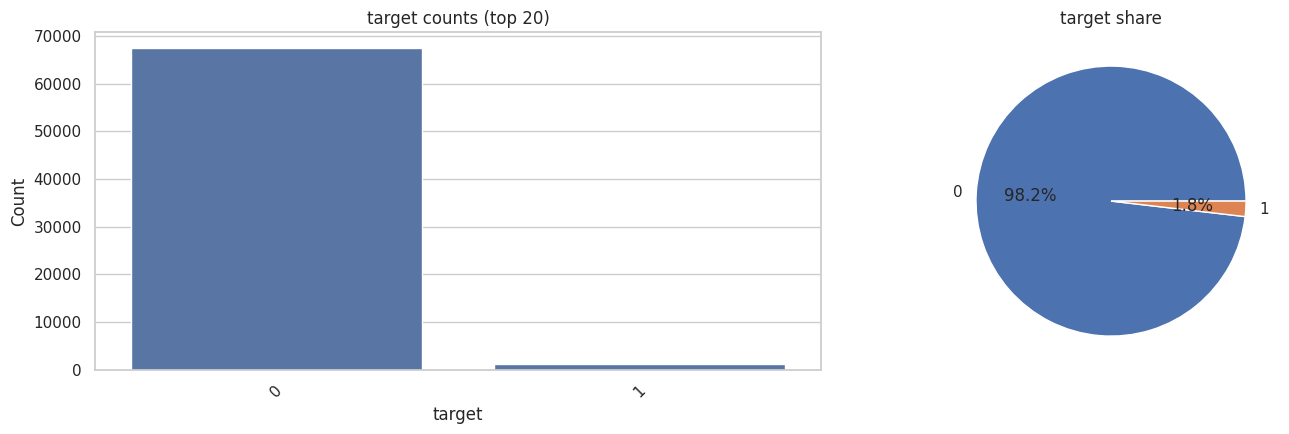

Default rate: 1.83% (1,258 defaults out of 68,654 loans)
A model that always predicts 'repaid' scores 98.17% accuracy and catches zero defaults.


In [7]:
plot_categorical(train, 'target')
prevalence = train['target'].mean()
print(f"Default rate: {prevalence:.2%} ({train['target'].sum():,} defaults out of {len(train):,} loans)")
print(f"A model that always predicts 'repaid' scores {1 - prevalence:.2%} accuracy and catches zero defaults.")

The target is heavily imbalanced, as expected for loan default. Consequences for the rest of the notebook:
- accuracy is not used for model selection; PR-AUC is (its random baseline equals the default rate printed above);
- imbalance is handled inside the models (class weights, focal loss, output-bias initialisation) rather than by resampling, so the validation and holdout sets keep the real-world class ratio;
- the decision threshold is tuned on validation data instead of using the default 0.5.

### 3.2 Country and lender — the generalisation problem

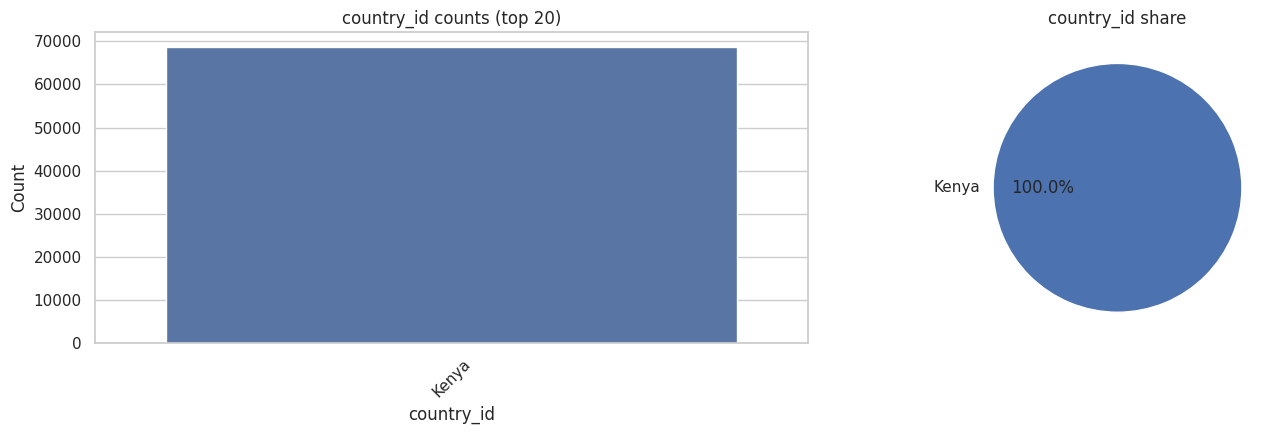

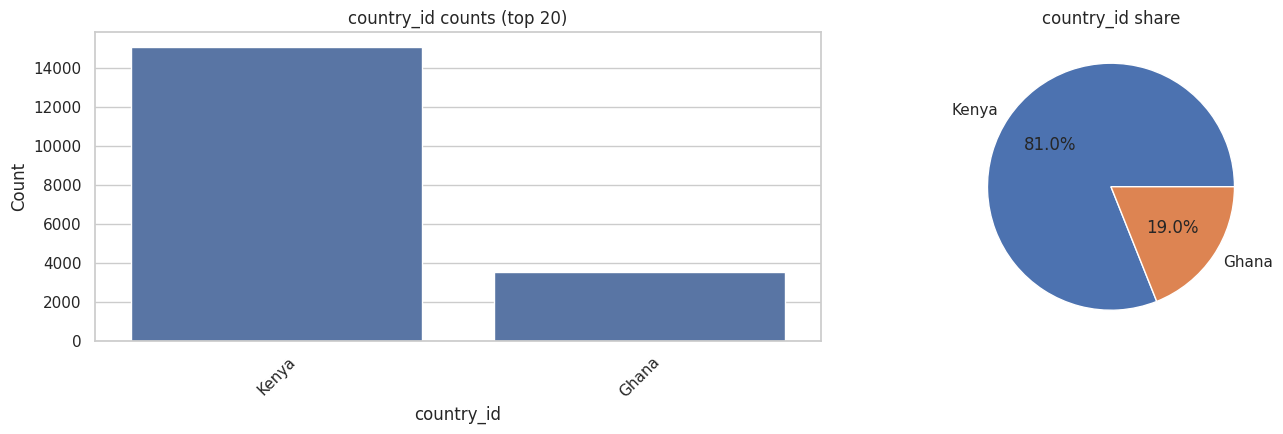

Train countries: {'Kenya': 68654}
Test countries : {'Kenya': 15069, 'Ghana': 3525}

Lenders in train: 4 | in test: 8 | only in test: [296540, 296542, 297182, 297183]


,lenders_in_test
country_id,
Ghana,"[297183, 296542, 296540, 245684, 297182]"
Kenya,"[267278, 251804, 245684, 267277]"


,loans,defaults,default_rate
lender_id,,,
267278,64653,784,1.21%
251804,3542,316,8.92%
267277,271,80,29.52%
245684,188,78,41.49%


In [8]:
plot_categorical(train, 'country_id')
plot_categorical(test, 'country_id')
print('Train countries:', train['country_id'].value_counts().to_dict())
print('Test countries :', test['country_id'].value_counts().to_dict())

train_lenders, test_lenders = set(train['lender_id']), set(test['lender_id'])
print(f"\nLenders in train: {len(train_lenders)} | in test: {len(test_lenders)} | only in test: {sorted(test_lenders - train_lenders)}")
display(test.groupby('country_id')['lender_id'].unique().to_frame('lenders_in_test'))
display(default_rate_table(train, 'lender_id').style.format({'default_rate': '{:.2%}'}))

The training data covers a single country, while the test set adds a new one (Ghana), served by lenders that never appear in training. Two consequences:
- `country_id` is constant in training, so it carries no learnable signal and is dropped.
- `lender_id` is informative within training but its Ghanaian values are unseen, so for those loans the model falls back to its "unknown lender" encoding. Section 8 simulates this situation with a leave-one-lender-out test, since Ghana labels are not available.

### 3.3 Loan type and new vs repeat borrowers

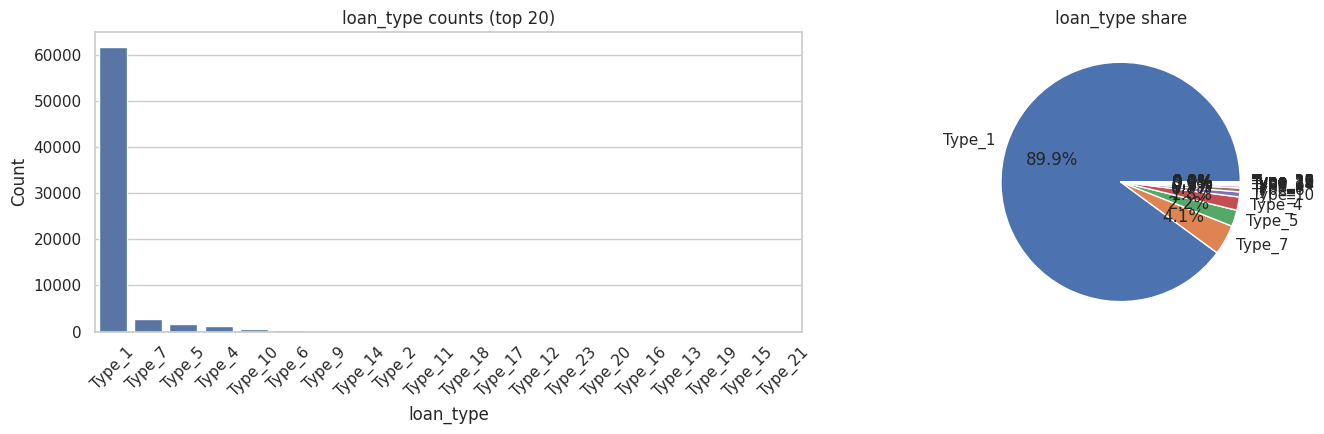

,loans,defaults,default_rate
loan_type,,,
Type_1,61723,520,0.84%
Type_7,2790,235,8.42%
Type_5,1521,122,8.02%
Type_4,1235,152,12.31%
Type_10,466,12,2.58%
Type_6,357,38,10.64%
Type_9,205,36,17.56%
Type_14,99,71,71.72%
Type_2,74,45,60.81%


Riskiest loan types with >=100 loans: {'Type_9': '17.56%', 'Type_4': '12.31%', 'Type_6': '10.64%'}
Loan types in test but not in train: ['Type_3', 'Type_8']


,loans,defaults,default_rate
New_versus_Repeat,,,
Repeat Loan,68087,1139,1.67%
New Loan,567,119,20.99%


In [9]:
plot_categorical(train, 'loan_type')
lt = default_rate_table(train, 'loan_type')
display(lt.head(15).style.format({'default_rate': '{:.2%}'}))
reliable = lt[lt['loans'] >= 100].sort_values('default_rate', ascending=False)
print('Riskiest loan types with >=100 loans:', reliable.head(3)['default_rate'].map('{:.2%}'.format).to_dict())
print(f"Loan types in test but not in train: {sorted(set(test['loan_type']) - set(train['loan_type']))}")

display(default_rate_table(train, 'New_versus_Repeat').style.format({'default_rate': '{:.2%}'}))

`loan_type` has a long tail: a few types dominate and many are rare. Rare categories get noisy default-rate estimates, so the one-hot encoder groups categories with fewer than 30 training loans into a single "infrequent" bucket, and unseen test categories map to that bucket instead of crashing the pipeline.

### 3.4 Loan amounts

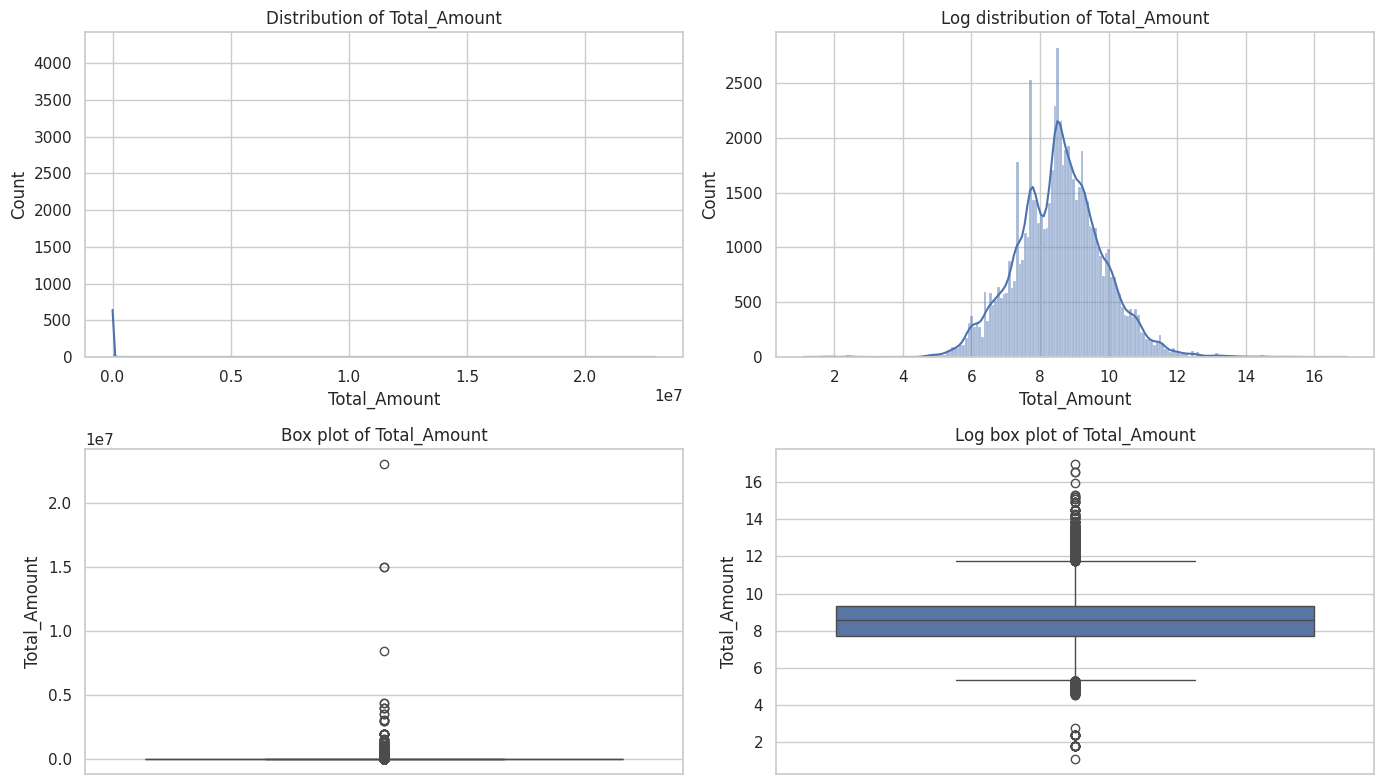

Skewness of raw amounts: {'Total_Amount': 103.8, 'Total_Amount_to_Repay': 104.6, 'Amount_Funded_By_Lender': 61.1, 'Lender_portion_to_be_repaid': 63.2}


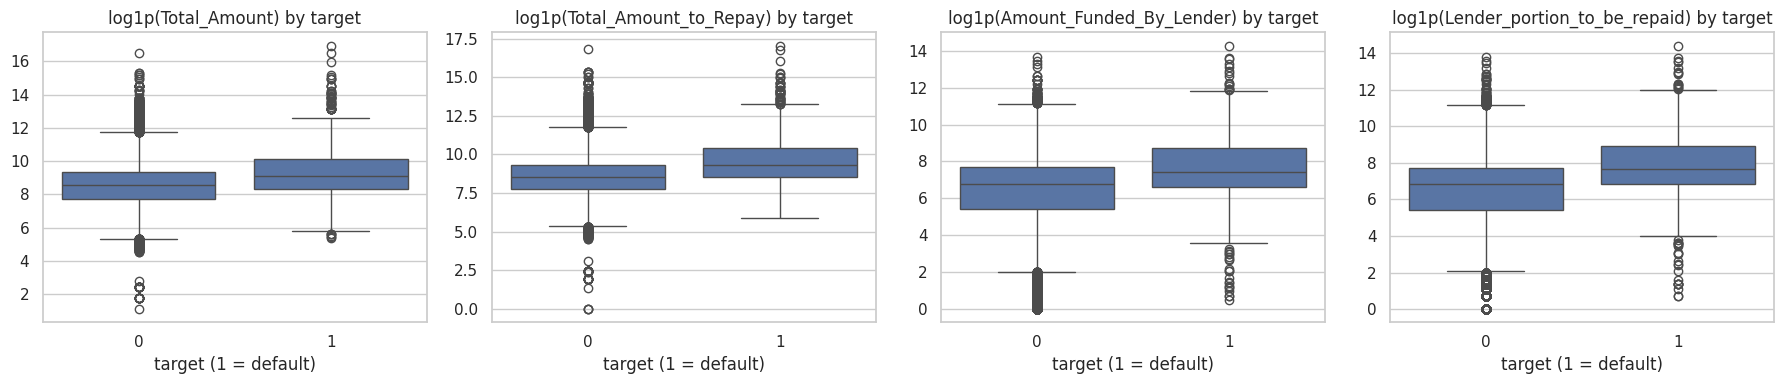

In [10]:
plot_continuous(train, 'Total_Amount', transform='log')

amount_cols = ['Total_Amount', 'Total_Amount_to_Repay', 'Amount_Funded_By_Lender', 'Lender_portion_to_be_repaid']
print('Skewness of raw amounts:', train[amount_cols].skew().round(1).to_dict())

fig, axs = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axs, amount_cols):
    sns.boxplot(x=train['target'], y=np.log1p(train[col]), ax=ax)
    ax.set(title=f'log1p({col}) by target', xlabel='target (1 = default)', ylabel='')
plt.tight_layout(); plt.show()

The amount columns are strongly right-skewed (skewness printed above), with a long tail of very large loans. Those points are plausible business loans rather than data errors, so they are kept, and `log1p` is applied: it compresses the tail, makes linear models and neural networks far less sensitive to extreme values, and leaves tree models unaffected (they only use ordering). The by-target boxplots show whether loan size alone separates defaulters.

### 3.5 Time and borrower history

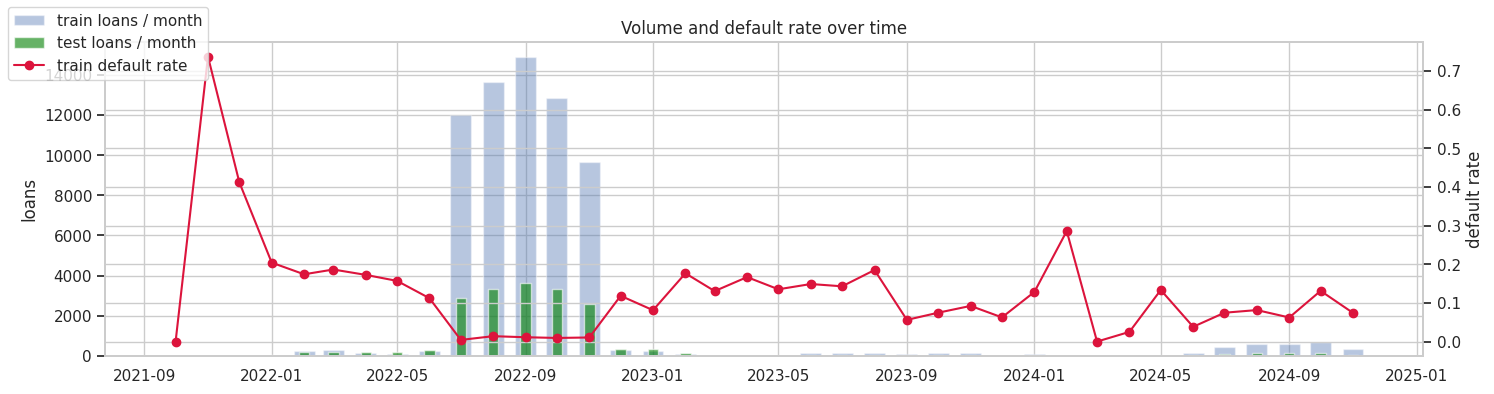

Train dates: 2021-10-04 -> 2024-11-14
Test dates : 2021-11-08 -> 2024-11-14

Customers in train: 6,540 | loans per customer: median 6, max 208, share of customers with >1 loan: 81.5%
Test customers also seen in train: 79.8%


In [11]:
for df in (train, test):
    df['_disb'] = pd.to_datetime(df['disbursement_date'])

monthly = train.set_index('_disb').resample('MS')['target'].agg(['size', 'mean'])
fig, ax1 = plt.subplots(figsize=(15, 4))
ax1.bar(monthly.index, monthly['size'], width=20, alpha=0.4, label='train loans / month')
ax1.set_ylabel('loans')
ax2 = ax1.twinx()
ax2.plot(monthly.index, monthly['mean'], color='crimson', marker='o', label='train default rate')
ax2.set_ylabel('default rate')
test_monthly = test.set_index('_disb').resample('MS').size()
ax1.bar(test_monthly.index, test_monthly.values, width=10, alpha=0.6, color='green', label='test loans / month')
fig.legend(loc='upper left'); ax1.set_title('Volume and default rate over time')
plt.tight_layout(); plt.show()
print(f"Train dates: {train['_disb'].min().date()} -> {train['_disb'].max().date()}")
print(f"Test dates : {test['_disb'].min().date()} -> {test['_disb'].max().date()}")

loans_per_customer = train.groupby('customer_id').size()
print(f"\nCustomers in train: {loans_per_customer.size:,} | loans per customer: median {loans_per_customer.median():.0f}, "
      f"max {loans_per_customer.max()}, share of customers with >1 loan: {(loans_per_customer > 1).mean():.1%}")
print(f"Test customers also seen in train: {test['customer_id'].isin(train['customer_id']).mean():.1%}")
for df in (train, test):
    df.drop(columns='_disb', inplace=True)

**EDA takeaways that drive the modelling choices**
1. **Severe imbalance** → PR-AUC for selection, in-model imbalance handling, tuned thresholds.
2. **Repeat borrowers** (many customers have several loans, printed above) → a random split leaks borrower identity, so all splits are grouped by `customer_id`; repeat borrowing also motivates *borrower-history* features (prior loans, time since last loan, whether the previous loan was still open).
3. **Skewed amounts** → `log1p` transforms plus pricing ratios (what the borrower pays relative to what they receive).
4. **Single training country and unseen test lenders** → `country_id` dropped; lender handled with an explicit unknown bucket; generalisation stress-tested in Section 8.
5. **Time coverage** → the default rate is not constant over time (plot above), and train and test overlap in time, so the calendar *year* is excluded: it would let models memorise period-specific default rates that do not transfer to future loans.

## 4. Feature Engineering & Leakage-Safe Preprocessing

Principles:
- **Only information available at disbursement** is used. Nothing derived from the target, and no repayment outcomes.
- **Identifiers are not features.** `customer_id` and `tbl_loan_id` are arbitrary numbers; feeding them as numeric columns (as the original starter code did) lets models pick up spurious ordering effects.
- **Transforms are fit on training data only.** Scaling and encoding live inside scikit-learn `Pipeline`s, so during cross-validation they are re-fit on each training fold.

Engineered features:

| Feature | Intuition |
|---|---|
| `log_*` amounts | Tame skew (Section 3.4). |
| `repay_to_amount_ratio`, `daily_cost_rate` | Effective price of credit; expensive credit is usually given to riskier borrowers and adds repayment strain. |
| `lender_repay_share` | Share of the repayment owed to the funding lender. |
| `term_mismatch` | Due date inconsistent with the stated duration (data-quality or restructuring signal). |
| `disb_month`, `disb_dayofweek`, `disb_day`, `disb_is_month_end` | Payday and seasonal effects. |
| `is_repeat` | New versus repeat borrower. |
| `cust_prior_loans`, `has_prev_loan`, `days_since_prev_loan`, `prev_loan_still_open`, `cust_loans_same_day`, `log_cust_prior_amount_mean`, `log_amount_vs_prior_mean` | Borrower behaviour: experience with the lender, borrowing frequency, overlapping loans ("loan stacking"), and whether this loan is unusually large for the borrower. |

Borrower-history features are computed over train and test loans together, strictly from each borrower's *earlier* loans and using no labels. This mirrors production, where a lender knows a customer's full borrowing history but not the outcome of loans that are still running.

In [12]:
AMOUNT_COLS = ['Total_Amount', 'Total_Amount_to_Repay', 'Amount_Funded_By_Lender', 'Lender_portion_to_be_repaid']


def engineer_features(df):
    out = df.copy()
    out['disbursement_date'] = pd.to_datetime(out['disbursement_date'])
    out['due_date'] = pd.to_datetime(out['due_date'])
    out['lender_id'] = out['lender_id'].astype(str)
    out['loan_type'] = out['loan_type'].astype(str)

    # Pricing / structure
    out['repay_to_amount_ratio'] = (out['Total_Amount_to_Repay'] / out['Total_Amount'].replace(0, np.nan)).fillna(1.0)
    out['daily_cost_rate'] = ((out['repay_to_amount_ratio'] - 1) / out['duration'].replace(0, np.nan)).fillna(0.0)
    out['lender_repay_share'] = (out['Lender_portion_to_be_repaid'] /
                                 out['Total_Amount_to_Repay'].replace(0, np.nan)).fillna(0.0)
    for c in AMOUNT_COLS:
        out[f'log_{c}'] = np.log1p(out[c].clip(lower=0))

    # Calendar
    out['term_mismatch'] = ((out['due_date'] - out['disbursement_date']).dt.days != out['duration']).astype(int)
    out['disb_month'] = out['disbursement_date'].dt.month
    out['disb_dayofweek'] = out['disbursement_date'].dt.dayofweek
    out['disb_day'] = out['disbursement_date'].dt.day
    out['disb_is_month_end'] = out['disbursement_date'].dt.is_month_end.astype(int)
    out['is_repeat'] = (out['New_versus_Repeat'] == 'Repeat Loan').astype(int)

    # Borrower history (earlier loans only, no labels)
    out = out.sort_values(['customer_id', 'disbursement_date', 'tbl_loan_id'])
    g = out.groupby('customer_id')
    out['cust_prior_loans'] = g.cumcount()
    out['has_prev_loan'] = (out['cust_prior_loans'] > 0).astype(int)
    prior_sum = g['Total_Amount'].cumsum() - out['Total_Amount']
    prior_mean = (prior_sum / out['cust_prior_loans'].replace(0, np.nan))
    out['log_cust_prior_amount_mean'] = np.log1p(prior_mean.fillna(0).clip(lower=0))
    out['log_amount_vs_prior_mean'] = np.where(out['has_prev_loan'] == 1,
                                               out['log_Total_Amount'] - out['log_cust_prior_amount_mean'], 0.0)
    out['days_since_prev_loan'] = np.log1p(g['disbursement_date'].diff().dt.days.fillna(0).clip(lower=0))
    out['prev_loan_still_open'] = (g['due_date'].shift() > out['disbursement_date']).astype(int)
    out['cust_loans_same_day'] = out.groupby(['customer_id', 'disbursement_date'])['ID'].transform('size')
    return out.sort_index()


NUM_FEATURES = (['log_' + c for c in AMOUNT_COLS] +
                ['Lender_portion_Funded', 'duration', 'repay_to_amount_ratio', 'daily_cost_rate',
                 'lender_repay_share', 'term_mismatch', 'disb_month', 'disb_dayofweek', 'disb_day',
                 'disb_is_month_end', 'is_repeat', 'cust_prior_loans', 'has_prev_loan',
                 'log_cust_prior_amount_mean', 'log_amount_vs_prior_mean', 'days_since_prev_loan',
                 'prev_loan_still_open', 'cust_loans_same_day'])
CAT_FEATURES = ['loan_type', 'lender_id']
FEATURES = NUM_FEATURES + CAT_FEATURES
EXCLUDED = ['ID', 'customer_id', 'tbl_loan_id', 'country_id', 'disbursement_date', 'due_date', 'calendar year']

combined = pd.concat([train.assign(_is_train=1), test.assign(_is_train=0)], ignore_index=True)
combined = engineer_features(combined)
train_fe = combined[combined['_is_train'] == 1].reset_index(drop=True)
train_fe['target'] = train_fe['target'].astype(int)   # concat with unlabelled test made it float
test_fe = combined[combined['_is_train'] == 0].drop(columns='target').reset_index(drop=True)

assert (train_fe['ID'].values == train['ID'].values).all() and (test_fe['ID'].values == test['ID'].values).all()
assert np.isfinite(train_fe[NUM_FEATURES].values).all() and np.isfinite(test_fe[NUM_FEATURES].values).all()
print(f"{len(NUM_FEATURES)} numeric + {len(CAT_FEATURES)} categorical features | excluded: {EXCLUDED}")
display(train_fe[FEATURES + ['target']].describe(include='all').T.head(30))

22 numeric + 2 categorical features | excluded: ['ID', 'customer_id', 'tbl_loan_id', 'country_id', 'disbursement_date', 'due_date', 'calendar year']


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
log_Total_Amount,68654.0,NaN,NaN,NaN,8.575373,1.263628,1.098612,7.738924,8.565983,9.345832,16.951005
log_Total_Amount_to_Repay,68654.0,NaN,NaN,NaN,8.595405,1.268962,0.0,7.753624,8.580356,9.363147,17.05085
log_Amount_Funded_By_Lender,68654.0,NaN,NaN,NaN,6.021324,2.755193,0.0,5.459586,6.820016,7.729142,14.285515
log_Lender_portion_to_be_repaid,68654.0,NaN,NaN,NaN,6.03928,2.764522,0.0,5.480639,6.840547,7.74846,14.415083
Lender_portion_Funded,68654.0,NaN,NaN,NaN,0.218679,0.129832,0.0,0.118712,0.3,0.3,1.168119
duration,68654.0,NaN,NaN,NaN,8.544586,13.343145,1.0,7.0,7.0,7.0,1096.0
repay_to_amount_ratio,68654.0,NaN,NaN,NaN,1.021674,0.055723,0.0,1.0,1.008157,1.030409,3.164865
daily_cost_rate,68654.0,NaN,NaN,NaN,0.002655,0.007042,-0.142857,0.0,0.001099,0.0039,0.309266
lender_repay_share,68654.0,NaN,NaN,NaN,0.21884,0.130088,0.0,0.118682,0.299963,0.300023,1.710112
term_mismatch,68654.0,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0


### 4.1 Grouped, stratified train / validation / holdout split

`StratifiedGroupKFold` keeps every customer entirely inside one split while preserving the default rate in each.

| Split | Share | Used for |
|---|---|---|
| Train | ≈71% | Fitting; 3-fold grouped cross-validation for scikit-learn tuning and learning curves |
| Validation | ≈15% | Early stopping (Keras), decision-threshold tuning, model selection |
| Holdout | ≈14% | Final, one-time ML vs DL comparison |

In [13]:
X_all, y_all, groups_all = train_fe[FEATURES], train_fe['target'].values, train_fe['customer_id'].values

outer = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED)              # 1/7 ≈ 14% holdout
trval_idx, hold_idx = next(outer.split(X_all, y_all, groups_all))
inner = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=SEED)              # 1/6 of the rest ≈ 15% val
tr_rel, va_rel = next(inner.split(X_all.iloc[trval_idx], y_all[trval_idx], groups_all[trval_idx]))
train_idx, val_idx = trval_idx[tr_rel], trval_idx[va_rel]

X_train, y_train, g_train = X_all.iloc[train_idx], y_all[train_idx], groups_all[train_idx]
X_val, y_val = X_all.iloc[val_idx], y_all[val_idx]
X_hold, y_hold, g_hold = X_all.iloc[hold_idx], y_all[hold_idx], groups_all[hold_idx]
X_test = test_fe[FEATURES]
X_SPLITS = {'train': X_train, 'val': X_val, 'holdout': X_hold, 'test': X_test}

# No borrower may appear in two splits
assert not (set(g_train) & set(groups_all[val_idx])) and not (set(g_train) & set(g_hold)) \
       and not (set(groups_all[val_idx]) & set(g_hold))

display(pd.DataFrame({'loans': [len(y_train), len(y_val), len(y_hold)],
                      'customers': [len(set(g_train)), len(set(groups_all[val_idx])), len(set(g_hold))],
                      'defaults': [y_train.sum(), y_val.sum(), y_hold.sum()],
                      'default_rate': [y_train.mean(), y_val.mean(), y_hold.mean()]},
                     index=['train', 'validation', 'holdout']).style.format({'default_rate': '{:.2%}'}))

# Fixed grouped CV folds inside the training split (shared by every search and learning curve)
CV_SPLITS = list(StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED).split(X_train, y_train, g_train))

,loans,customers,defaults,default_rate
train,49210,4663,883,1.79%
validation,9440,944,210,2.22%
holdout,10004,933,165,1.65%


### 4.2 Preprocessing pipeline

- **Numeric:** `StandardScaler` (needed by logistic regression, SVM and neural networks; harmless for trees).
- **Categorical:** `OneHotEncoder` with `min_frequency=30` (rare categories pooled) and `handle_unknown='infrequent_if_exist'` (unseen test lenders and loan types go to the pooled bucket, or all zeros if no pool exists, instead of raising an error).

The preprocessor is created fresh inside every model pipeline, so it is always fit on exactly the data the model trains on.

In [14]:
def make_preprocessor(num_features=NUM_FEATURES, cat_features=CAT_FEATURES):
    return ColumnTransformer([
        ('num', StandardScaler(), num_features),
        ('cat', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=30, sparse_output=False), cat_features),
    ])

_prep = make_preprocessor().fit(X_train)
print(f"Model input width after encoding: {_prep.transform(X_train.head()).shape[1]} columns")

Model input width after encoding: 37 columns


---
# 5. Part 1 — Traditional Machine Learning (Scikit-Learn)

Three model families with very different inductive biases:

| Model | Decision boundary | Why it is here |
|---|---|---|
| **Logistic Regression** | Linear in the features, outputs calibrated-ish probabilities | The industry-standard, explainable credit-scoring baseline. |
| **Random Forest** | Axis-aligned, non-linear, captures interactions automatically | Strong tabular learner, robust to scaling and outliers. |
| **Support Vector Machine** | Maximum-margin; linear, or RBF via a Nyström kernel approximation | Exact RBF-kernel SVC scales O(n²–n³) in memory/time on ~50k rows; `Nystroem` + `LinearSVC` approximates the RBF kernel in roughly linear time, so the kernel choice itself becomes a tunable hyperparameter. |

Workflow: **(5.1)** untuned baselines → **(5.2)** randomized hyperparameter search with grouped CV (every candidate logged to TensorBoard) → **(5.3)** learning curves → **(5.4)** feature importance.

### 5.1 Baselines (library defaults, no imbalance handling)

[LogisticRegression] at the library-default threshold it flags 120 of 9440 validation loans (recall 0.505)


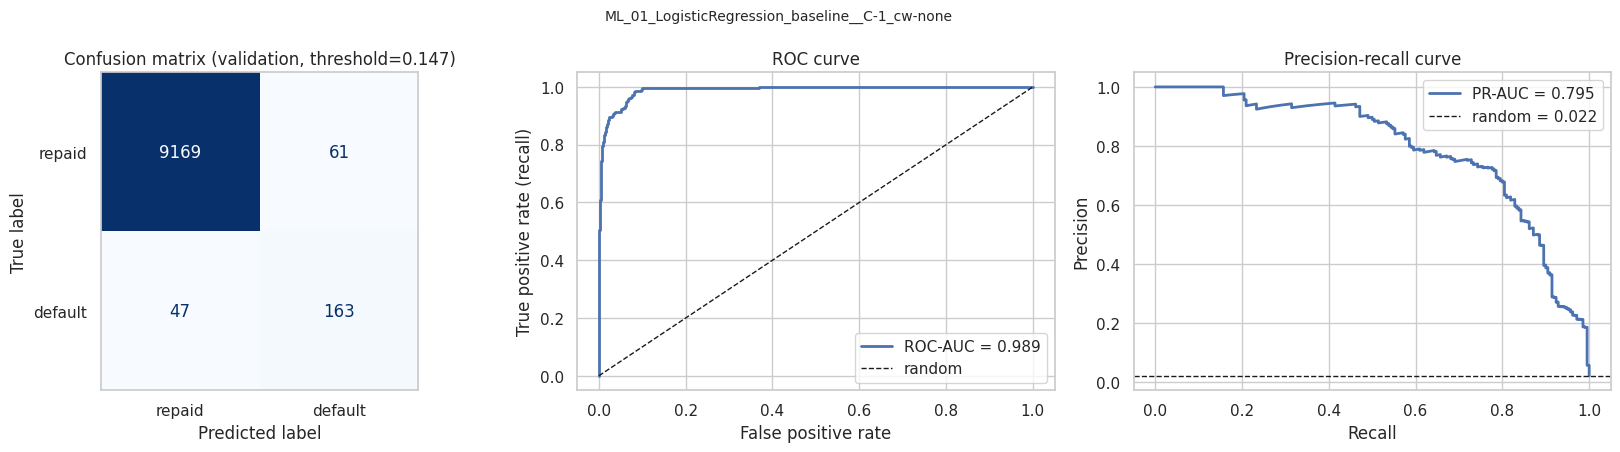

ML_01_LogisticRegression_baseline__C-1_cw-none
  val PR-AUC=0.7954 | ROC-AUC=0.9889 | F1=0.7512 | precision=0.7277 | recall=0.7762 @ threshold=0.1473
[RandomForest] at the library-default threshold it flags 162 of 9440 validation loans (recall 0.710)


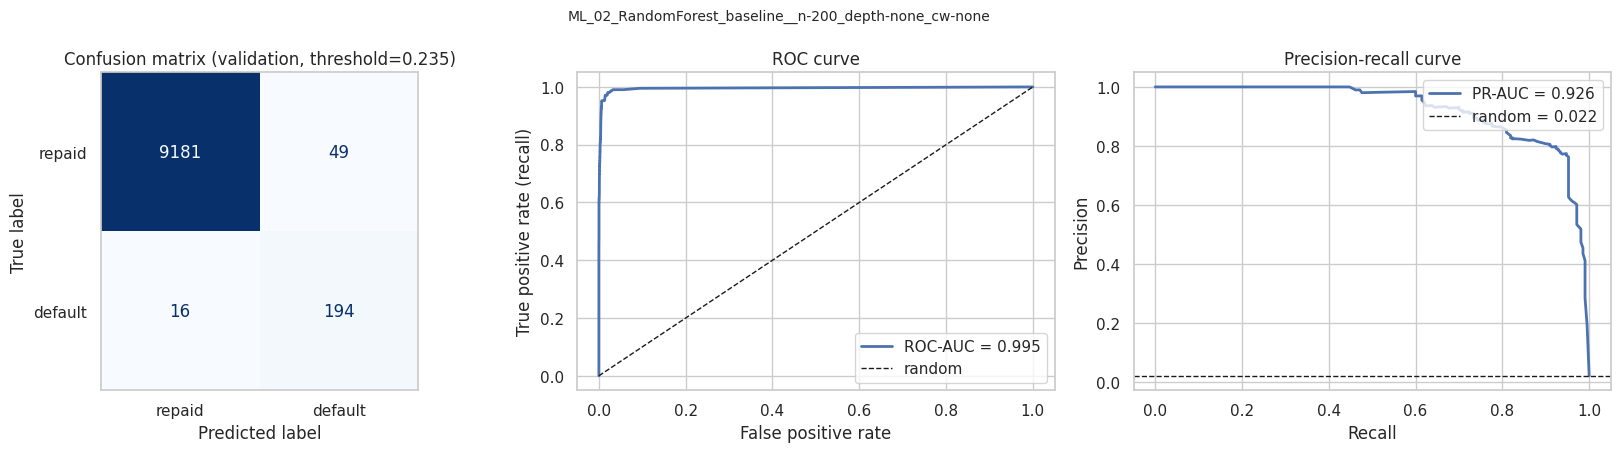

ML_02_RandomForest_baseline__n-200_depth-none_cw-none
  val PR-AUC=0.9256 | ROC-AUC=0.9953 | F1=0.8565 | precision=0.7984 | recall=0.9238 @ threshold=0.235
[SVM] at the library-default threshold it flags 120 of 9440 validation loans (recall 0.505)


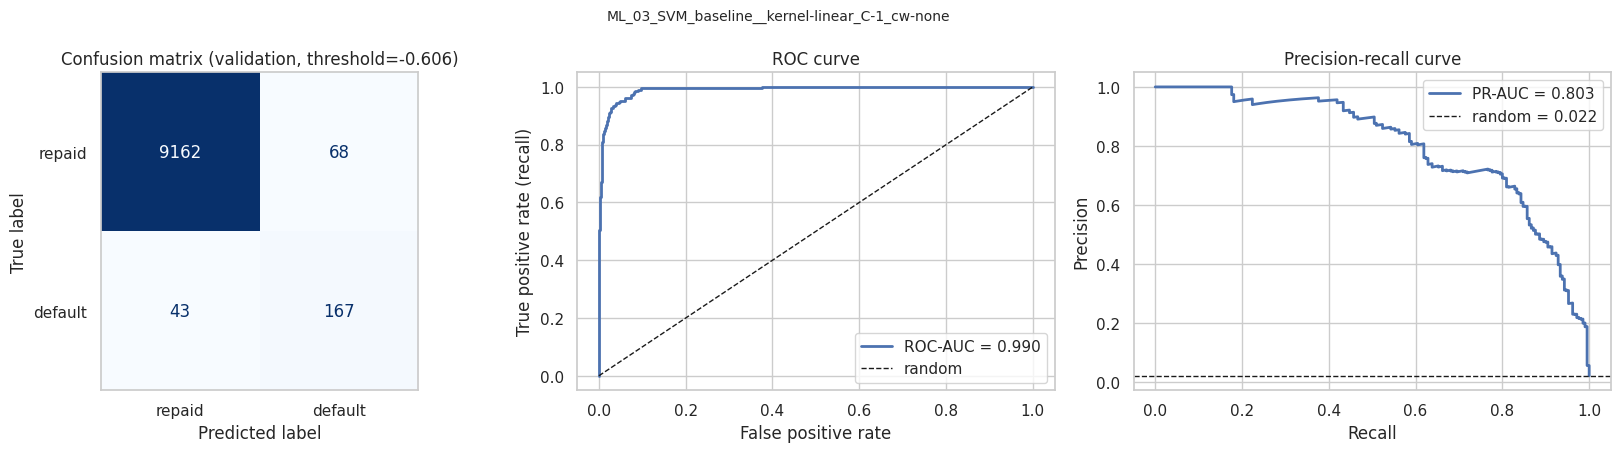

ML_03_SVM_baseline__kernel-linear_C-1_cw-none
  val PR-AUC=0.8029 | ROC-AUC=0.9902 | F1=0.7506 | precision=0.7106 | recall=0.7952 @ threshold=-0.6063


In [15]:
baseline_specs = [
    ('LogisticRegression', LogisticRegression(max_iter=2000, random_state=SEED), {'C': 1.0, 'cw': 'none'}),
    ('RandomForest', RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1), {'n': 200, 'depth': 'none', 'cw': 'none'}),
    ('SVM', LinearSVC(dual='auto', max_iter=5000, random_state=SEED), {'kernel': 'linear', 'C': 1.0, 'cw': 'none'}),
]

exp_idx = 1
for family, est, shown in baseline_specs:
    pipe = Pipeline([('prep', make_preprocessor()), ('clf', est)]).fit(X_train, y_train)
    name = run_name('ML', exp_idx, f'{family}_baseline', **shown)
    MODELS[name] = {'kind': 'sklearn', 'model': pipe}
    # Default-threshold behaviour, to show why threshold tuning matters
    default_pred = pipe.predict(X_val)
    print(f"[{family}] at the library-default threshold it flags {default_pred.sum()} of {len(y_val)} validation loans "
          f"(recall {recall_score(y_val, default_pred):.3f})")
    record_experiment(name, family, {'stage': 'baseline', **shown}, y_val, get_scores(pipe, X_val))
    exp_idx += 1

Reading the baselines: at the library-default threshold, models trained without imbalance handling flag very few loans as defaults (printed recall above), because predicting "repaid" is almost always right. That is a *thresholding* problem, not necessarily a *ranking* problem: PR-AUC and ROC-AUC evaluate the ranking regardless of threshold, and the confusion matrices are drawn at the F1-optimal validation threshold. Tuning below tests whether class weighting and regularisation also improve the ranking itself.

### 5.2 Hyperparameter tuning (RandomizedSearchCV, grouped 3-fold CV, optimising PR-AUC)

| Model | Search space | Rationale |
|---|---|---|
| Logistic Regression | `C` ∈ log-uniform[1e-3, 1e2], penalty ∈ {L1, L2}, class weight ∈ {none, balanced} | Regularisation strength; L1 performs feature selection. |
| Random Forest | trees ∈ [150, 400], max depth ∈ {6…18, none}, min samples per leaf ∈ [1, 60], max features ∈ {sqrt, 0.3, 0.5}, class weight ∈ {none, balanced, balanced_subsample} | Depth and leaf size control variance; deep fully-grown trees memorise rare defaults. |
| SVM | kernel ∈ {linear, RBF-Nyström(300 components)}, γ ∈ log-uniform[1e-3, 1], `C` ∈ log-uniform[1e-3, 10], class weight ∈ {none, balanced} | Linear vs non-linear margin; `C` trades margin width against training errors. |

Randomized search samples the space instead of exhausting a grid, which covers continuous ranges far better for the same compute. Each search reports CV PR-AUC on held-out folds *and* on training folds; the difference (`overfit_gap`) is logged so over-fitting candidates are visible in TensorBoard's HParams tab.

In [16]:
N_ITER = 3 if QUICK_RUN else 15
SHORT = {'clf__C': 'C', 'clf__penalty': 'pen', 'clf__class_weight': 'cw', 'clf__n_estimators': 'n',
         'clf__max_depth': 'depth', 'clf__min_samples_leaf': 'leaf', 'clf__max_features': 'mf',
         'kmap': 'kernel', 'kmap__gamma': 'gamma'}


def tune_and_log(family, pipeline, param_distributions, idx, n_iter=N_ITER):
    """Randomized search with grouped CV; logs every candidate to TensorBoard; returns the fitted search."""
    search = RandomizedSearchCV(pipeline, param_distributions, n_iter=n_iter, cv=CV_SPLITS,
                                scoring={'pr_auc': 'average_precision', 'roc_auc': 'roc_auc'}, refit='pr_auc',
                                return_train_score=True, n_jobs=-1, random_state=SEED, verbose=0)
    search.fit(X_train, y_train)
    res = pd.DataFrame(search.cv_results_)
    param_cols = [c for c in res.columns if c.startswith('param_')]
    rows = []
    for i, row in res.iterrows():
        params = {SHORT.get(c[6:], c[6:]): row[c] for c in param_cols}
        name = run_name('ML', idx, f'{family}_search_cand{i:02d}', **params)
        gap = row['mean_train_pr_auc'] - row['mean_test_pr_auc']
        log_run(name, {'family': family, 'stage': 'search', **params},
                {'cv/pr_auc_mean': row['mean_test_pr_auc'], 'cv/pr_auc_std': row['std_test_pr_auc'],
                 'cv/roc_auc_mean': row['mean_test_roc_auc'], 'cv/train_pr_auc_mean': row['mean_train_pr_auc'],
                 'cv/overfit_gap': gap})
        rows.append({**{k: _fmt(v) for k, v in params.items()}, 'cv_pr_auc': row['mean_test_pr_auc'],
                     'cv_pr_auc_std': row['std_test_pr_auc'], 'cv_roc_auc': row['mean_test_roc_auc'],
                     'train_pr_auc': row['mean_train_pr_auc'], 'overfit_gap': gap})
    table = pd.DataFrame(rows).sort_values('cv_pr_auc', ascending=False)
    print(f"{family}: {len(table)} candidates | best CV PR-AUC = {search.best_score_:.4f}")
    display(table.head(5).style.format(precision=4))
    return search


def register_tuned(family, search, idx):
    """Evaluate the refit best pipeline on validation and record it as a named experiment."""
    best = search.best_estimator_
    params = {SHORT.get(k, k): v for k, v in search.best_params_.items()}
    name = run_name('ML', idx, f'{family}_tuned', **params)
    MODELS[name] = {'kind': 'sklearn', 'model': best}
    record_experiment(name, family, {'stage': 'tuned', **params,
                                     'cv_pr_auc': search.best_score_}, y_val, get_scores(best, X_val))
    return name

TUNED = {}

LogisticRegression: 15 candidates | best CV PR-AUC = 0.8258


,C,cw,pen,cv_pr_auc,cv_pr_auc_std,cv_roc_auc,train_pr_auc,overfit_gap
1,4.57,none,l1,0.8258,0.0078,0.9890,0.8474,0.0216
14,0.916,none,l1,0.8036,0.0063,0.9864,0.8223,0.0187
4,1.01,balanced,l1,0.8031,0.0176,0.9897,0.8190,0.0158
6,14.5,balanced,l2,0.7633,0.0181,0.9885,0.7798,0.0165
12,0.191,none,l2,0.7615,0.0097,0.9844,0.7741,0.0126


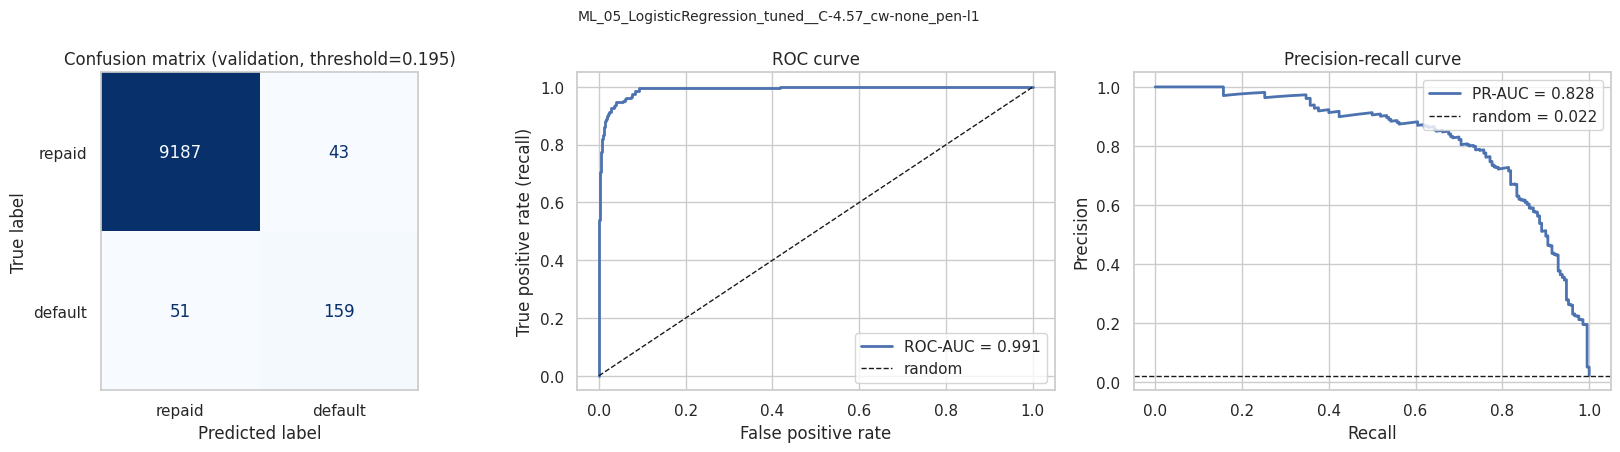

ML_05_LogisticRegression_tuned__C-4.57_cw-none_pen-l1
  val PR-AUC=0.8277 | ROC-AUC=0.9907 | F1=0.7718 | precision=0.7871 | recall=0.7571 @ threshold=0.1949


In [17]:
# ── Logistic Regression ──
lr_space = {'clf__C': loguniform(1e-3, 1e2), 'clf__penalty': ['l1', 'l2'], 'clf__class_weight': [None, 'balanced']}
lr_pipe = Pipeline([('prep', make_preprocessor()),
                    ('clf', LogisticRegression(solver='liblinear', max_iter=3000, random_state=SEED))])
lr_search = tune_and_log('LogisticRegression', lr_pipe, lr_space, idx=exp_idx)
TUNED['LogisticRegression'] = register_tuned('LogisticRegression', lr_search, idx=exp_idx + 1)
exp_idx += 2

In [ ]:
# ── Random Forest ──
rf_space = {'clf__n_estimators': randint(150, 401), 'clf__max_depth': [6, 8, 10, 14, 18, None],
            'clf__min_samples_leaf': randint(1, 61), 'clf__max_features': ['sqrt', 0.3, 0.5],
            'clf__class_weight': [None, 'balanced', 'balanced_subsample']}
rf_pipe = Pipeline([('prep', make_preprocessor()),
                    ('clf', RandomForestClassifier(random_state=SEED, n_jobs=1))])   # parallelism at search level
rf_search = tune_and_log('RandomForest', rf_pipe, rf_space, idx=exp_idx)
TUNED['RandomForest'] = register_tuned('RandomForest', rf_search, idx=exp_idx + 1)
exp_idx += 2

In [ ]:
# ── Support Vector Machine (linear or RBF via Nyström) ──
svm_space = [
    {'kmap': ['passthrough'], 'clf__C': loguniform(1e-3, 1e1), 'clf__class_weight': [None, 'balanced']},
    {'kmap': [Nystroem(kernel='rbf', n_components=300, random_state=SEED)], 'kmap__gamma': loguniform(1e-3, 1e0),
     'clf__C': loguniform(1e-3, 1e1), 'clf__class_weight': [None, 'balanced']},
]
svm_pipe = Pipeline([('prep', make_preprocessor()), ('kmap', 'passthrough'),
                     ('clf', LinearSVC(dual='auto', max_iter=5000, random_state=SEED))])
svm_search = tune_and_log('SVM', svm_pipe, svm_space, idx=exp_idx)
TUNED['SVM'] = register_tuned('SVM', svm_search, idx=exp_idx + 1)
exp_idx += 2

In [ ]:
ml_table = pd.DataFrame(RESULTS).query("paradigm == 'ML'").set_index('run')
display(ml_table.drop(columns=['paradigm']).style.format(precision=4)
        .background_gradient(subset=['val_pr_auc'], cmap='Greens'))

### 5.3 Learning curves

For each tuned model, the training split is subsampled (10% → 100%) and PR-AUC is measured on the training subsample and on the held-out CV folds.

How to read them:
- **Large, persistent gap** between training and CV curves → high variance (over-fitting); more data or stronger regularisation would help.
- **Both curves low and close** → high bias (under-fitting); the model or the features are not expressive enough.
- **CV curve still rising at 100%** → more data would likely help; **flat** → the model has extracted what these features can offer.

Curves are also written to TensorBoard (Scalars tab, x-axis = number of training loans).

In [ ]:
train_sizes = np.linspace(0.1, 1.0, 4 if QUICK_RUN else 6)
fig, axs = plt.subplots(1, len(TUNED), figsize=(6 * len(TUNED), 4.5), sharey=True)
lc_summary = []
for ax, (family, name) in zip(np.atleast_1d(axs), TUNED.items()):
    sizes, tr_scores, cv_scores = learning_curve(clone(MODELS[name]['model']), X_train, y_train, cv=CV_SPLITS,
                                                 train_sizes=train_sizes, scoring='average_precision',
                                                 shuffle=True, random_state=SEED, n_jobs=-1)
    tr_m, cv_m, cv_s = tr_scores.mean(1), cv_scores.mean(1), cv_scores.std(1)
    ax.plot(sizes, tr_m, 'o-', label='training PR-AUC')
    ax.plot(sizes, cv_m, 'o-', label='CV PR-AUC')
    ax.fill_between(sizes, cv_m - cv_s, cv_m + cv_s, alpha=0.2)
    ax.axhline(y_train.mean(), color='k', ls=':', lw=1, label='random')
    ax.set(title=f'{family} (tuned)', xlabel='training loans', ylabel='PR-AUC'); ax.legend()
    with tf.summary.create_file_writer(os.path.join(LOG_DIR, f'ML_LearningCurve_{family}_tuned')).as_default():
        for s, a, b in zip(sizes, tr_m, cv_m):
            tf.summary.scalar('learning_curve/train_pr_auc', a, step=int(s))
            tf.summary.scalar('learning_curve/cv_pr_auc', b, step=int(s))
    lc_summary.append({'model': family, 'final_train_pr_auc': tr_m[-1], 'final_cv_pr_auc': cv_m[-1],
                       'gap': tr_m[-1] - cv_m[-1], 'cv_gain_last_step': cv_m[-1] - cv_m[-2]})
plt.tight_layout(); plt.show()

lc_df = pd.DataFrame(lc_summary).set_index('model')
lc_df['diagnosis'] = np.select(
    [lc_df['gap'] > 0.15, (lc_df['gap'] < 0.05) & (lc_df['final_cv_pr_auc'] < 3 * y_train.mean())],
    ['high variance: regularise / more data', 'high bias: richer model or features'], 'reasonable bias-variance balance')
lc_df.loc[lc_df['cv_gain_last_step'] > 0.01, 'diagnosis'] += ' (still improving with data)'
display(lc_df.style.format(precision=4))

The automatic diagnosis column applies the rules above (gap > 0.15 → variance; small gap with CV PR-AUC under 3× the random baseline → bias). Typical patterns for this kind of data: the Random Forest shows the largest train–CV gap because trees can isolate individual rare defaults, while Logistic Regression and the linear SVM sit close together with little gap (their capacity, not the data volume, is the limit). Where the CV curve is still climbing at full size, more labelled loans would pay off more than further tuning.

### 5.4 Feature importance

Permutation importance on the validation set: shuffle one raw feature at a time and measure the drop in PR-AUC. It works for any model (including the SVM margin), operates on original columns rather than one-hot fragments, and reflects what the model actually relies on for unseen borrowers, unlike impurity-based Random Forest importance, which is biased toward high-cardinality features.

In [ ]:
best_ml_name = max(TUNED.values(), key=lambda n: next(r['val_pr_auc'] for r in RESULTS if r['run'] == n))
best_ml_model = MODELS[best_ml_name]['model']
print(f'Best traditional model on validation PR-AUC: {best_ml_name}')

pi = permutation_importance(best_ml_model, X_val, y_val, scoring='average_precision',
                            n_repeats=3 if QUICK_RUN else 10, random_state=SEED, n_jobs=-1)
imp = pd.DataFrame({'feature': FEATURES, 'importance': pi.importances_mean, 'std': pi.importances_std}) \
        .sort_values('importance', ascending=False)
fig, ax = plt.subplots(figsize=(9, 7))
top = imp.head(20).iloc[::-1]
ax.barh(top['feature'], top['importance'], xerr=top['std'], color='steelblue')
ax.set(title=f'Permutation importance (drop in validation PR-AUC)\n{best_ml_name.split("__")[0]}', xlabel='ΔPR-AUC')
plt.tight_layout(); plt.show()
best_ml_family = next(f for f, n in TUNED.items() if n == best_ml_name)
log_run(f'ML_FeatureImportance__{best_ml_family}_tuned_permutation', figures={'permutation_importance': fig})

lr_model = MODELS[TUNED['LogisticRegression']]['model']
coef = pd.Series(lr_model.named_steps['clf'].coef_.ravel(),
                 index=lr_model.named_steps['prep'].get_feature_names_out()).sort_values()
print('Logistic Regression: strongest risk-increasing (+) and risk-decreasing (−) standardized coefficients')
display(pd.concat([coef.tail(8)[::-1], coef.head(8)]).to_frame('coefficient').style.format(precision=3))

Permutation importance can be near zero or slightly negative for features that are redundant with others (for example the several amount columns): shuffling one leaves the information available through its correlated partners. The logistic-regression coefficients give the *direction* of each effect on the standardized scale, which is what a credit officer would need to explain a decision.

---
# 6. Part 2 — Deep Learning (TensorFlow / Keras)

Part 1 established how far classical models get on these features. Part 2 asks whether neural networks can do better on the same problem, using **exactly the same splits, features and metrics**, so the comparison is fair.

Neural networks are not automatically better on tabular data: tree ensembles often match or beat them on a few dozen hand-crafted features. Where they can add value here is in **learned embeddings** for categorical variables (lenders, loan types) and in smooth decision functions that may extrapolate differently from trees. The experiments are designed to isolate one change at a time:

| # | Experiment | API | What it tests |
|---|---|---|---|
| DL_01 | Small MLP, plain cross-entropy | Sequential | Baseline network with no imbalance handling |
| DL_02 | Same MLP + class weights | Sequential | Effect of re-weighting the rare class |
| DL_03 | Deeper MLP + BatchNorm + Dropout + L2 + class weights | Sequential | Capacity plus regularisation |
| DL_04 | Wide & deep with categorical embeddings + class weights | Functional | Embeddings vs one-hot; linear "wide" path + non-linear "deep" path |
| DL_05 | Wide & deep + focal loss + prior-based output bias | Functional | Focal loss as an alternative imbalance strategy |
| DL_06+ | Hyperparameter sweep around the best architecture | — | Learning rate × dropout × width/depth |

**Input pipeline.** All data is fed through `tf.data.Dataset` pipelines: cached in memory, shuffled with a fixed seed every epoch (training only), batched, and prefetched so the next batch is prepared while the current one trains. The wide & deep model receives a *dictionary* dataset with separate tensors for numeric features and each categorical index.

**Training protocol.** Adam optimiser, early stopping on validation PR-AUC (best weights restored), learning-rate halving on plateau, and a TensorBoard callback per run (scalars, weight histograms) plus an HParams summary.

### 6.1 Data preparation and `tf.data` pipelines

In [ ]:
BATCH_SIZE = 512
EPOCHS = 3 if QUICK_RUN else 60

# (a) One-hot inputs for the Sequential MLPs: reuse the scikit-learn preprocessor, fit on train only
prep_dl = make_preprocessor().fit(X_train)
ONEHOT = {s: prep_dl.transform(X).astype('float32') for s, X in X_SPLITS.items()}

# (b) Numeric + integer category indices for the embedding model. Index 0 = unknown/unseen category
num_scaler = StandardScaler().fit(X_train[NUM_FEATURES])
cat_encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1).fit(X_train[CAT_FEATURES])
VOCAB = {c: len(cats) + 1 for c, cats in zip(CAT_FEATURES, cat_encoder.categories_)}


def to_embed_inputs(X):
    idx = cat_encoder.transform(X[CAT_FEATURES]).astype('int32') + 1
    feats = {'numeric': num_scaler.transform(X[NUM_FEATURES]).astype('float32')}
    feats.update({c: idx[:, [j]] for j, c in enumerate(CAT_FEATURES)})
    return feats

EMBED = {s: to_embed_inputs(X) for s, X in X_SPLITS.items()}
DL_INPUTS = {'onehot': ONEHOT, 'embed': EMBED}
Y = {'train': y_train.astype('float32'), 'val': y_val.astype('float32'), 'holdout': y_hold.astype('float32')}


def make_dataset(features, labels=None, training=False, batch_size=BATCH_SIZE):
    """tf.data pipeline: cache -> (shuffle) -> batch -> prefetch."""
    ds = tf.data.Dataset.from_tensor_slices(features if labels is None else (features, labels)).cache()
    if training:
        ds = ds.shuffle(buffer_size=len(labels), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)


# Imbalance handling quantities
neg, pos = np.bincount(y_train)
CLASS_WEIGHT = {0: len(y_train) / (2 * neg), 1: len(y_train) / (2 * pos)}
PRIOR_BIAS = float(np.log(pos / neg))   # sigmoid(PRIOR_BIAS) = training default rate

print(f"One-hot input width: {ONEHOT['train'].shape[1]} | embedding vocab sizes: {VOCAB}")
print(f"Class weights: {{0: {CLASS_WEIGHT[0]:.3f}, 1: {CLASS_WEIGHT[1]:.2f}}} | prior output bias: {PRIOR_BIAS:.3f}")
sample_batch = next(iter(make_dataset(EMBED['train'], Y['train'], training=True)))
print('Example wide&deep batch:', {k: tuple(v.shape) for k, v in sample_batch[0].items()}, '| labels', tuple(sample_batch[1].shape))

Two imbalance tools are used, and they should not be combined naively:
- **Class weights** (`{0: ~0.5, 1: ~27}`-style, printed above) make each default count as much as ~50 repaid loans in the loss. The network then behaves as if the classes were balanced, so its raw outputs are inflated probabilities. Ranking is unaffected, and the validation-tuned threshold absorbs the shift.
- **Output-bias initialisation** sets the final bias to log(pos/neg), so the untrained network already predicts the true base rate. This removes the large, wasted loss of the first epochs. It is used *without* class weights (DL_05), because with class weights the effective prior is 0.5 and the matching bias would be 0.

### 6.2 Model builders (Sequential and Functional APIs)

In [ ]:
def dl_metrics():
    return [keras.metrics.AUC(curve='PR', name='pr_auc'), keras.metrics.AUC(name='roc_auc'),
            keras.metrics.Precision(name='precision'), keras.metrics.Recall(name='recall')]


def _output_bias(cfg):
    return keras.initializers.Constant(PRIOR_BIAS) if cfg.get('bias_init') else 'zeros'


def build_sequential_mlp(cfg, input_dim):
    """Sequential API: Dense -> [BatchNorm] -> ReLU -> [Dropout], repeated, then a sigmoid output."""
    reg = regularizers.l2(cfg['l2']) if cfg['l2'] else None
    stack = [keras.Input(shape=(input_dim,), name='onehot_features')]
    for u in cfg['units']:
        stack.append(layers.Dense(u, kernel_regularizer=reg, use_bias=not cfg['batchnorm']))
        if cfg['batchnorm']:
            stack.append(layers.BatchNormalization())
        stack.append(layers.Activation('relu'))
        if cfg['dropout']:
            stack.append(layers.Dropout(cfg['dropout']))
    stack.append(layers.Dense(1, activation='sigmoid', bias_initializer=_output_bias(cfg), name='default_probability'))
    return keras.Sequential(stack, name=cfg['label'])


def build_wide_deep(cfg):
    """Functional API: numeric features + learned embeddings -> deep tower; numeric features -> linear 'wide' path.
    The two logits are added before the sigmoid."""
    reg = regularizers.l2(cfg['l2']) if cfg['l2'] else None
    num_in = keras.Input(shape=(len(NUM_FEATURES),), name='numeric')
    cat_ins, embs = [], []
    for c in CAT_FEATURES:
        inp = keras.Input(shape=(1,), name=c, dtype='int32')
        dim = int(min(16, round(1.6 * VOCAB[c] ** 0.56)))          # embedding-size rule of thumb
        embs.append(layers.Flatten()(layers.Embedding(VOCAB[c], dim, name=f'embedding_{c}')(inp)))
        cat_ins.append(inp)
    x = layers.Concatenate(name='deep_input')([num_in] + embs)
    for i, u in enumerate(cfg['units']):
        x = layers.Dense(u, kernel_regularizer=reg, use_bias=not cfg['batchnorm'], name=f'deep_dense_{i}')(x)
        if cfg['batchnorm']:
            x = layers.BatchNormalization(name=f'deep_bn_{i}')(x)
        x = layers.Activation('relu')(x)
        if cfg['dropout']:
            x = layers.Dropout(cfg['dropout'])(x)
    deep_logit = layers.Dense(1, bias_initializer=_output_bias(cfg), name='deep_logit')(x)
    wide_logit = layers.Dense(1, use_bias=False, name='wide_logit')(num_in)
    out = layers.Activation('sigmoid', name='default_probability')(layers.Add(name='wide_plus_deep')([deep_logit, wide_logit]))
    return keras.Model(inputs=[num_in] + cat_ins, outputs=out, name=cfg['label'])


def build_model(cfg):
    return build_sequential_mlp(cfg, ONEHOT['train'].shape[1]) if cfg['arch'] == 'sequential' else build_wide_deep(cfg)


keras.utils.set_random_seed(SEED)
build_model({'label': 'WideDeep_preview', 'arch': 'widedeep', 'units': (128, 64), 'dropout': 0.3,
             'l2': 1e-4, 'batchnorm': True}).summary()

### 6.3 Training loop with TensorBoard tracking

In [ ]:
DL_HISTORY = {}


def dl_run_name(idx, cfg):
    return run_name('DL', idx, cfg['label'], u=cfg['units'], do=cfg['dropout'], l2=cfg['l2'],
                    bn=int(cfg['batchnorm']), loss=cfg['loss'] + (f"g{cfg['focal_gamma']}" if cfg['loss'] == 'focal' else ''),
                    cw='balanced' if cfg['class_weight'] else 'none', bias='prior' if cfg.get('bias_init') else 'zero',
                    lr=cfg['lr'], bs=BATCH_SIZE)


def train_dl_experiment(idx, cfg, show=True):
    keras.utils.set_random_seed(SEED)                       # identical initialisation & shuffling per run
    name = dl_run_name(idx, cfg)
    run_dir = os.path.join(LOG_DIR, name)
    data = DL_INPUTS['onehot' if cfg['arch'] == 'sequential' else 'embed']

    model = build_model(cfg)
    loss = (keras.losses.BinaryFocalCrossentropy(gamma=cfg['focal_gamma']) if cfg['loss'] == 'focal'
            else keras.losses.BinaryCrossentropy())
    model.compile(optimizer=keras.optimizers.Adam(cfg['lr']), loss=loss, metrics=dl_metrics())

    ds_train = make_dataset(data['train'], Y['train'], training=True)
    ds_val = make_dataset(data['val'], Y['val'])
    cbs = [keras.callbacks.TensorBoard(log_dir=run_dir, histogram_freq=1, profile_batch=0),
           keras.callbacks.EarlyStopping(monitor='val_pr_auc', mode='max', patience=8, restore_best_weights=True),
           keras.callbacks.ReduceLROnPlateau(monitor='val_pr_auc', mode='max', factor=0.5, patience=3, min_lr=1e-5)]
    history = model.fit(ds_train, validation_data=ds_val, epochs=EPOCHS, verbose=0, callbacks=cbs,
                        class_weight=CLASS_WEIGHT if cfg['class_weight'] else None)

    epochs_run = len(history.history['loss'])
    best_epoch = int(np.argmax(history.history['val_pr_auc'])) + 1
    MODELS[name] = {'kind': 'keras', 'model': model, 'data_key': 'onehot' if cfg['arch'] == 'sequential' else 'embed'}
    DL_HISTORY[name] = history.history
    val_scores = model.predict(ds_val, verbose=0).ravel()
    hparams = {k: v for k, v in cfg.items() if k != 'label'}
    hparams.update({'params': model.count_params(), 'epochs_run': epochs_run, 'best_epoch': best_epoch, 'batch_size': BATCH_SIZE})
    m = record_experiment(name, cfg['arch'], hparams, y_val, val_scores, show=show)
    print(f'  {model.count_params():,} parameters | stopped after {epochs_run} epochs (best epoch {best_epoch})')
    return name, m


def plot_histories(names, ncols=2):
    """Per-epoch learning curves: loss and PR-AUC, training vs validation."""
    rows = int(np.ceil(len(names) / ncols))
    fig, axs = plt.subplots(rows, ncols * 2, figsize=(9 * ncols, 3.4 * rows), squeeze=False)
    for i, name in enumerate(names):
        h = DL_HISTORY[name]; r, c = divmod(i, ncols)
        a1, a2 = axs[r, 2 * c], axs[r, 2 * c + 1]
        short = name.split('__')[0]
        a1.plot(h['loss'], label='train'); a1.plot(h['val_loss'], label='validation'); a1.set_title(f'{short} | loss', fontsize=8)
        a2.plot(h['pr_auc'], label='train'); a2.plot(h['val_pr_auc'], label='validation'); a2.set_title(f'{short} | PR-AUC', fontsize=8)
        best = int(np.argmax(h['val_pr_auc']))
        a2.axvline(best, color='grey', ls=':', lw=1)
        for a in (a1, a2):
            a.set_xlabel('epoch'); a.legend(fontsize=7)
    for j in range(len(names), rows * ncols):
        r, c = divmod(j, ncols); axs[r, 2 * c].remove(); axs[r, 2 * c + 1].remove()
    plt.tight_layout(); plt.show()

### 6.4 Architecture and imbalance-strategy experiments

In [ ]:
BASE = {'units': (64,), 'dropout': 0.0, 'l2': 0.0, 'batchnorm': False, 'loss': 'bce',
        'focal_gamma': 2.0, 'class_weight': False, 'bias_init': False, 'lr': 1e-3}
DL_EXPERIMENTS = [
    {**BASE, 'label': 'SeqMLP_baseline', 'arch': 'sequential'},
    {**BASE, 'label': 'SeqMLP_classweights', 'arch': 'sequential', 'class_weight': True},
    {**BASE, 'label': 'SeqMLP_deep_regularised', 'arch': 'sequential', 'units': (128, 64), 'dropout': 0.3,
     'l2': 1e-4, 'batchnorm': True, 'class_weight': True},
    {**BASE, 'label': 'WideDeep_embeddings_classweights', 'arch': 'widedeep', 'units': (128, 64), 'dropout': 0.3,
     'l2': 1e-4, 'batchnorm': True, 'class_weight': True},
    {**BASE, 'label': 'WideDeep_embeddings_focal_priorbias', 'arch': 'widedeep', 'units': (128, 64), 'dropout': 0.3,
     'l2': 1e-4, 'batchnorm': True, 'loss': 'focal', 'bias_init': True},
]

dl_idx = 1
DL_CONFIGS = {}
for cfg in DL_EXPERIMENTS:
    name, _ = train_dl_experiment(dl_idx, cfg)
    DL_CONFIGS[name] = cfg
    dl_idx += 1

### 6.5 Deep learning learning curves

How to read the per-epoch curves:
- The dotted line marks the epoch with the best validation PR-AUC (the weights that were kept).
- **Training loss is not directly comparable to validation loss** in the class-weighted runs: Keras applies class weights to the training loss only, so the training loss is measured on a re-weighted problem. Compare the *shapes* and the PR-AUC panel instead.
- Training PR-AUC is computed with dropout active, so a regularised model can show training PR-AUC *below* validation PR-AUC early on; that is expected, not a bug.
- Validation PR-AUC that peaks and then decays while training PR-AUC keeps rising is over-fitting; early stopping cuts training there. Very noisy validation curves reflect how few defaults the validation set contains (each default moves PR-AUC noticeably).

In [ ]:
plot_histories(list(DL_CONFIGS))

### 6.6 Hyperparameter sweep around the best architecture

The best of the five experiments above (by validation PR-AUC) is re-trained over a grid of learning rate × dropout × network size. All runs appear in TensorBoard's HParams tab, where the parallel-coordinates view shows which settings matter.

In [ ]:
dl_val = pd.DataFrame(RESULTS).query("paradigm == 'DL'").set_index('run')['val_pr_auc']
best_arch_name = dl_val.loc[list(DL_CONFIGS)].idxmax()
base_cfg = DL_CONFIGS[best_arch_name]
print(f'Sweeping around: {best_arch_name}')

grid = [(lr, do, units) for lr in (1e-3, 3e-4) for do in (0.2, 0.4) for units in ((128, 64), (256, 128, 64))]
if QUICK_RUN:
    grid = grid[:2]
for lr, do, units in grid:
    cfg = {**base_cfg, 'label': f"Sweep_{base_cfg['label']}", 'lr': lr, 'dropout': do, 'units': units,
           'batchnorm': True, 'l2': base_cfg['l2'] or 1e-4}
    name, _ = train_dl_experiment(dl_idx, cfg, show=False)
    DL_CONFIGS[name] = cfg
    dl_idx += 1

dl_table = pd.DataFrame(RESULTS).query("paradigm == 'DL'").set_index('run')
display(dl_table.drop(columns=['paradigm']).sort_values('val_pr_auc', ascending=False)
        .style.format(precision=4).background_gradient(subset=['val_pr_auc'], cmap='Greens'))

best_dl_name = dl_table['val_pr_auc'].idxmax()
print(f'Best deep learning model on validation PR-AUC: {best_dl_name}')
plot_histories([best_dl_name], ncols=1)

How to interpret the deep learning results:
- **DL_01 vs DL_02** isolates class weighting. Expect a similar PR-AUC (ranking) but very different recall at the default 0.5 cut-off; if PR-AUC also improves, the re-weighted gradient is helping the network learn minority-class structure rather than just shifting its outputs.
- **DL_02 vs DL_03** isolates capacity and regularisation. A deeper network only helps if the validation curve does not start decaying early.
- **DL_03 vs DL_04** isolates embeddings and the wide path. Embeddings let lenders and loan types with similar risk share representations; with only a handful of lenders, the gain over one-hot may be small.
- **DL_04 vs DL_05** compares class weights with focal loss + prior bias. Focal loss down-weights easy, confidently-correct repaid loans; it often gives better-calibrated scores than heavy class weights.
- In the sweep table, differences smaller than the spread between neighbouring configurations are within noise for a validation set with only a few hundred defaults.

---
## 7. ML vs DL — Final Comparison on the Holdout Set

Model selection so far used only training and validation data. Now one champion per family (the tuned Logistic Regression, Random Forest and SVM, plus the best neural network) is scored **once** on the untouched holdout set, each at the threshold it chose on validation.

With only a few hundred holdout defaults, single-number differences can be noise, so 95% confidence intervals are estimated with a **customer-level bootstrap**: whole borrowers are resampled, because loans from the same borrower are correlated.

In [ ]:
def predict_scores(name, split):
    entry = MODELS[name]
    if entry['kind'] == 'sklearn':
        return get_scores(entry['model'], X_SPLITS[split])
    return entry['model'].predict(make_dataset(DL_INPUTS[entry['data_key']][split]), verbose=0).ravel()


def grouped_bootstrap(y, groups, score_dict, metric=average_precision_score, n_boot=200 if QUICK_RUN else 1000):
    """Customer-level bootstrap. Returns {model: array of metric values} computed on identical resamples."""
    rng = np.random.default_rng(SEED)
    order = np.argsort(groups, kind='stable')
    _, starts, counts = np.unique(groups[order], return_index=True, return_counts=True)
    out = {k: [] for k in score_dict}
    for _ in range(n_boot):
        pick = rng.integers(0, len(starts), len(starts))
        idx = order[np.concatenate([np.arange(s, s + c) for s, c in zip(starts[pick], counts[pick])])]
        if y[idx].sum() == 0:
            continue
        for k, s in score_dict.items():
            out[k].append(metric(y[idx], s[idx]))
    return {k: np.array(v) for k, v in out.items()}


CHAMPIONS = {**{f'{f} (tuned)': n for f, n in TUNED.items()}, 'Deep learning (best)': best_dl_name}
val_lookup = pd.DataFrame(RESULTS).set_index('run')
HOLD_SCORES, holdout_rows = {}, []
for label, name in CHAMPIONS.items():
    s = predict_scores(name, 'holdout')
    HOLD_SCORES[label] = s
    thr = val_lookup.loc[name, 'val_threshold']
    m = compute_metrics(y_hold, s, thr)
    fig = plot_evaluation(f'HOLDOUT | {label} | {name}', y_hold, s, thr, split='holdout')
    log_run(f'FINAL_holdout__{name}', {'champion': label}, {f'holdout/{k}': v for k, v in m.items()},
            figures={'holdout_evaluation': fig})
    plt.close(fig)
    holdout_rows.append({'model': label, 'paradigm': 'DL' if name.startswith('DL') else 'ML',
                         'val_pr_auc': val_lookup.loc[name, 'val_pr_auc'], **{f'holdout_{k}': v for k, v in m.items()}})

boot = grouped_bootstrap(y_hold, g_hold, HOLD_SCORES)
summary = pd.DataFrame(holdout_rows).set_index('model')
summary['holdout_pr_auc_95ci'] = [f"[{np.percentile(boot[k], 2.5):.3f}, {np.percentile(boot[k], 97.5):.3f}]" for k in summary.index]
print(f'Holdout: {len(y_hold):,} loans, {y_hold.sum()} defaults (random PR-AUC = {y_hold.mean():.4f})')
display(summary.style.format(precision=4).background_gradient(subset=['holdout_pr_auc'], cmap='Greens'))

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(15, 5.5))
for label, s in HOLD_SCORES.items():
    fpr, tpr, _ = roc_curve(y_hold, s)
    axs[0].plot(fpr, tpr, lw=2, label=f'{label}: {roc_auc_score(y_hold, s):.3f}')
    p, r, _ = precision_recall_curve(y_hold, s)
    axs[1].plot(r, p, lw=2, label=f'{label}: {average_precision_score(y_hold, s):.3f}')
axs[0].plot([0, 1], [0, 1], 'k--', lw=1)
axs[0].set(title='Holdout ROC curves (legend: ROC-AUC)', xlabel='False positive rate', ylabel='Recall')
axs[1].axhline(y_hold.mean(), color='k', ls='--', lw=1, label=f'random: {y_hold.mean():.3f}')
axs[1].set(title='Holdout precision-recall curves (legend: PR-AUC)', xlabel='Recall', ylabel='Precision')
for a in axs: a.legend(fontsize=8)
plt.tight_layout(); plt.show()
log_run('FINAL_holdout__ROC_PR_overlay_all_champions', figures={'roc_pr_overlay': fig})

fig, axs = plt.subplots(1, len(CHAMPIONS), figsize=(4.6 * len(CHAMPIONS), 4))
for ax, (label, name) in zip(axs, CHAMPIONS.items()):
    thr = val_lookup.loc[name, 'val_threshold']
    ConfusionMatrixDisplay(confusion_matrix(y_hold, (HOLD_SCORES[label] >= thr).astype(int)),
                           display_labels=['repaid', 'default']).plot(ax=ax, cmap='Blues', colorbar=False, values_format='d')
    ax.set_title(label, fontsize=10); ax.grid(False)
plt.suptitle('Holdout confusion matrices (thresholds tuned on validation)'); plt.tight_layout(); plt.show()

In [ ]:
# Paired comparison: best traditional model vs best deep learning model on identical bootstrap resamples
ml_labels = [k for k in CHAMPIONS if not CHAMPIONS[k].startswith('DL')]
best_ml_label = summary.loc[ml_labels, 'val_pr_auc'].idxmax()          # chosen on validation, not holdout
dl_label = 'Deep learning (best)'
diff = boot[best_ml_label] - boot[dl_label]
lo, hi = np.percentile(diff, [2.5, 97.5])
point = summary.loc[best_ml_label, 'holdout_pr_auc'] - summary.loc[dl_label, 'holdout_pr_auc']
verdict = ('the traditional model is significantly better' if lo > 0 else
           'the deep learning model is significantly better' if hi < 0 else
           'the difference is NOT statistically significant at this sample size')
print(f"Holdout PR-AUC: {best_ml_label} − {dl_label} = {point:+.4f}  (95% CI [{lo:+.4f}, {hi:+.4f}]) → {verdict}")

# Business view: if a credit officer can only review the riskiest k% of loans, what share of defaults is caught?
rows = []
for label, s in HOLD_SCORES.items():
    order = np.argsort(-s)
    for k in (0.02, 0.05, 0.10, 0.20):
        top = order[:int(np.ceil(k * len(s)))]
        rows.append({'model': label, 'review_top': f'{k:.0%}', 'defaults_caught (recall)': y_hold[top].sum() / y_hold.sum(),
                     'precision': y_hold[top].mean()})
display(pd.DataFrame(rows).pivot(index='model', columns='review_top', values='defaults_caught (recall)')
        .style.format('{:.1%}').set_caption('Share of holdout defaults captured when reviewing the riskiest k% of loans'))

**Reading the comparison**
- The bootstrap verdict printed above is the honest headline. If the interval for the difference includes zero, the data cannot separate the two paradigms, and the simpler, cheaper, more explainable model should be preferred.
- Validation and holdout PR-AUC should be close for every champion. A large drop from validation to holdout signals over-fitting to the validation set through model selection or threshold tuning.
- The "review the riskiest k%" table translates PR-AUC into an operational question. A lender rarely acts on a single threshold; it decides how many applications it can afford to review or decline, and this table shows how many defaults each model catches at each capacity.
- Precision at the tuned threshold is typically low (most flagged loans still repay). That is inherent to a 1.8% base rate: even a strong model that raises the default probability tenfold for flagged loans still leaves most of them repaying.

## 8. Error Analysis

Where does the best model (selected on validation PR-AUC) fail? Holdout predictions are broken down by segment to see whether misses are concentrated in particular lenders, loan types, borrower types or loan sizes.

In [ ]:
final_label = summary['val_pr_auc'].idxmax()
final_name = CHAMPIONS[final_label]
final_thr = val_lookup.loc[final_name, 'val_threshold']
print(f'Model analysed: {final_label} -> {final_name}  (threshold {final_thr:.4g})')

ea = train_fe.iloc[hold_idx].copy()
ea['score'] = HOLD_SCORES[final_label]
ea['pred'] = (ea['score'] >= final_thr).astype(int)
ea['outcome'] = np.select([(ea.pred == 1) & (ea.target == 1), (ea.pred == 0) & (ea.target == 1),
                           (ea.pred == 1) & (ea.target == 0)], ['TP', 'FN', 'FP'], 'TN')
ea['amount_quintile'] = pd.qcut(ea['Total_Amount'], 5, duplicates='drop').astype(str)
ea['prior_loans_bucket'] = pd.cut(ea['cust_prior_loans'], [-1, 0, 2, 5, 10, np.inf],
                                  labels=['0', '1-2', '3-5', '6-10', '>10']).astype(str)
print(classification_report(ea['target'], ea['pred'], target_names=['repaid', 'default'], digits=3))


def segment_report(df, col, min_loans=50):
    g = df.groupby(col)
    t = pd.DataFrame({'loans': g.size(), 'defaults': g['target'].sum(), 'default_rate': g['target'].mean(),
                      'flagged': g['pred'].sum(), 'TP': g['outcome'].apply(lambda s: (s == 'TP').sum()),
                      'FN': g['outcome'].apply(lambda s: (s == 'FN').sum())})
    t['recall'] = t['TP'] / t['defaults'].replace(0, np.nan)
    t['precision'] = t['TP'] / t['flagged'].replace(0, np.nan)
    return t[t['loans'] >= min_loans].sort_values('loans', ascending=False)

fmt = {'default_rate': '{:.2%}', 'recall': '{:.1%}', 'precision': '{:.1%}'}
for col in ['lender_id', 'loan_type', 'New_versus_Repeat', 'amount_quintile', 'prior_loans_bucket']:
    print(f'\n── Holdout errors by {col} ──')
    display(segment_report(ea, col).head(12).style.format(fmt, na_rep='–'))

In [ ]:
# How do missed defaults (FN) differ from caught defaults (TP) and from correct repaid loans (TN)?
profile_cols = ['Total_Amount', 'duration', 'repay_to_amount_ratio', 'cust_prior_loans', 'days_since_prev_loan',
                'prev_loan_still_open', 'is_repeat', 'score']
display(ea.groupby('outcome')[profile_cols].median().loc[['TP', 'FN', 'FP', 'TN']].style.format(precision=3)
        .set_caption('Median feature values by outcome'))

fig, ax = plt.subplots(figsize=(10, 4))
for lab, color in [('TN', 'tab:blue'), ('FP', 'tab:orange'), ('FN', 'tab:red'), ('TP', 'tab:green')]:
    sub = ea.loc[ea['outcome'] == lab, 'score']
    if len(sub) > 1:
        sns.kdeplot(sub, ax=ax, label=f'{lab} (n={len(sub)})', color=color, common_norm=False, warn_singular=False)
ax.axvline(final_thr, color='k', ls='--', label='threshold')
ax.set(title='Score distribution by outcome (holdout)', xlabel='risk score'); ax.legend()
plt.tight_layout(); plt.show()

print('Hardest missed defaults (lowest scores among actual defaults):')
display(ea[ea['target'] == 1].nsmallest(10, 'score')[['loan_type', 'lender_id', 'New_versus_Repeat', 'Total_Amount',
                                                     'duration', 'cust_prior_loans', 'score']])

**What to look for in the error analysis**
- **Segments with low recall** (tables above) are where the model is blind: often rare loan types or the smallest lenders, where the model has seen too few defaults to learn their pattern.
- **Missed defaults that look like good loans:** if FN medians sit close to TN medians on every feature, those defaults are not predictable from these columns. They are likely driven by information the dataset does not contain (income shocks, other debts), which is a data limitation rather than a modelling one.
- **False positives** are mostly loans that resemble defaulters (similar pricing, history and size) but repaid. For a lender, a false positive is a declined good customer, while a false negative is a credit loss; the threshold should ultimately be set from those two costs, not from F1.

### 8.1 Robustness: leave-one-lender-out (proxy for the unseen country)

Ghana's loans come from lenders absent in training, and no Ghanaian labels exist to test on. The closest available simulation: for each large training lender, retrain the best traditional model on all *other* lenders (with `lender_id` removed) and test on the held-out lender. The drop relative to in-distribution performance indicates how much accuracy to expect on a new lender or market.

ROC-AUC is the fairest comparison across lenders because it does not depend on each lender's default rate; PR-AUC is also shown as a multiple of that lender's base rate ("lift").

In [ ]:
lender_stats = train_fe.groupby('lender_id')['target'].agg(['size', 'sum'])
eligible = lender_stats[(lender_stats['size'] >= 500) & (lender_stats['sum'] >= 20)].index.tolist()
feats_no_lender = NUM_FEATURES + ['loan_type']

if len(eligible) < 2:
    print(f'Only {len(eligible)} lender(s) with >=500 loans and >=20 defaults; leave-one-lender-out is not informative here.')
else:
    rows = []
    for L in eligible:
        tr_mask = train_fe['lender_id'] != L
        model = clone(best_ml_model).set_params(prep=make_preprocessor(NUM_FEATURES, ['loan_type']))
        model.fit(train_fe.loc[tr_mask, feats_no_lender], train_fe.loc[tr_mask, 'target'])
        yt = train_fe.loc[~tr_mask, 'target'].values
        st = get_scores(model, train_fe.loc[~tr_mask, feats_no_lender])
        rows.append({'held_out_lender': L, 'loans': len(yt), 'default_rate': yt.mean(),
                     'roc_auc_unseen_lender': roc_auc_score(yt, st),
                     'pr_auc_lift_unseen_lender': average_precision_score(yt, st) / yt.mean()})
    lolo = pd.DataFrame(rows).set_index('held_out_lender')
    in_dist = summary.loc[best_ml_label]
    print(f"In-distribution holdout ({best_ml_label}): ROC-AUC={in_dist['holdout_roc_auc']:.3f} | "
          f"PR-AUC lift={in_dist['holdout_pr_auc'] / y_hold.mean():.1f}x")
    display(lolo.style.format({'default_rate': '{:.2%}', 'roc_auc_unseen_lender': '{:.3f}', 'pr_auc_lift_unseen_lender': '{:.1f}x'}))
    with tf.summary.create_file_writer(os.path.join(LOG_DIR, f'ROBUSTNESS_leave_one_lender_out__{best_ml_label.split()[0]}')).as_default():
        for i, (L, r) in enumerate(lolo.iterrows()):
            tf.summary.scalar('lolo/roc_auc_unseen_lender', r['roc_auc_unseen_lender'], step=i)

## 9. Dataset Limitations & Conclusions

**Limitations of the dataset**
1. **Single training country.** All labels come from Kenya; the test set adds Ghana with entirely new lenders. Lending products, repayment culture and macro conditions differ across markets, so performance on Ghanaian loans is unknown and probably lower (Section 8.1 estimates the size of an unseen-lender drop).
2. **Thin borrower information.** There are no borrower attributes (income, employment, credit-bureau history, mobile-money behaviour). Models must infer risk from loan terms and borrowing history alone, which caps achievable performance; many missed defaults look identical to good loans on every available column.
3. **Truncated history.** Borrower-history features only see loans inside this dataset's window; a borrower's earlier loans, or loans with other providers, are invisible.
4. **Unknown label definition.** The precise meaning of "default" (days past due, write-off) is not documented, which matters for how scores should be used.
5. **Few positives.** About 1.8% defaults means the validation and holdout sets contain only a few hundred defaults each; metric differences of a few points are within noise (see the bootstrap intervals).
6. **Temporal drift.** The default rate moves over time and train/test overlap in time, so a random (even grouped) split slightly overstates performance on genuinely future loans. An out-of-time split would be the stricter test if dates allowed it.
7. **Anonymised categories.** Lender and loan-type codes cannot be interpreted, limiting domain-driven feature engineering.

**Conclusions** (the cell below prints the data-driven summary for this run)
- Framing credit scoring as binary classification works, but only with imbalance-aware evaluation: accuracy is uninformative, and threshold choice dominates precision/recall.
- Leakage control (grouping by borrower, dropping identifiers, fitting transforms per fold) matters more for honest results than model choice.
- The ML vs DL verdict and the bootstrap interval below decide whether the extra complexity of deep learning is justified on this data.
- To improve materially, the next step is better data rather than bigger models: labelled loans from more countries and lenders, and borrower-level attributes.

In [ ]:
ml_best_row, dl_row = summary.loc[best_ml_label], summary.loc[dl_label]
print('══════════════ RUN SUMMARY ══════════════')
print(f"Base default rate (holdout)        : {y_hold.mean():.2%}")
print(f"Best traditional model (by val)    : {best_ml_label:<28} holdout PR-AUC {ml_best_row['holdout_pr_auc']:.4f} {ml_best_row['holdout_pr_auc_95ci']} | ROC-AUC {ml_best_row['holdout_roc_auc']:.4f}")
print(f"Best deep learning model (by val)  : {best_dl_name.split('__')[0]:<28} holdout PR-AUC {dl_row['holdout_pr_auc']:.4f} {dl_row['holdout_pr_auc_95ci']} | ROC-AUC {dl_row['holdout_roc_auc']:.4f}")
print(f"ML − DL holdout PR-AUC             : {point:+.4f} (95% CI [{lo:+.4f}, {hi:+.4f}]) → {verdict}")
print(f"Lift over random (best overall)    : {summary['holdout_pr_auc'].max() / y_hold.mean():.1f}x")
print(f"Model used for the submission      : {final_label} -> {final_name}")

## 10. TensorBoard Dashboard

In [ ]:
test_scores = predict_scores(final_name, 'test')
sub = pd.DataFrame({'ID': test_fe['ID'], 'target': (test_scores >= final_thr).astype(int)})
assert (sub['ID'].values == test['ID'].values).all() and len(sub) == len(test)

sub_path = os.path.join(persistent_project_dir, f"submission_{final_name.split('__')[0]}.csv")
sub.to_csv(sub_path, index=False)
print(f'Saved {sub_path}')
display(sub.head())

shift = pd.DataFrame({'country': test_fe['country_id'], 'score': test_scores, 'flagged': sub['target']}) \
          .groupby('country').agg(loans=('score', 'size'), mean_score=('score', 'mean'), flagged_rate=('flagged', 'mean'))
display(shift.style.format({'mean_score': '{:.4f}', 'flagged_rate': '{:.2%}'})
        .set_caption('Test-set predictions by country — a large gap signals distribution shift, not necessarily real risk'))

### Live TensorBoard dashboard

- **Scalars:** filter runs with regexes such as `ML_.*tuned`, `DL_0[1-5]`, `Sweep`, `FINAL_holdout`, `LearningCurve`.
- **HParams:** table and parallel-coordinates views across all search candidates and sweep runs (sort by `val/pr_auc` or `cv/pr_auc_mean`).
- **Images:** confusion matrices, ROC and PR curves per run; feature importance.
- **Histograms / Distributions:** Keras weight evolution per epoch.

Logs from all sessions live under `tensorboard_logs/`; point `--logdir` at a single `session_*` folder to view one run of the notebook.

In [ ]:
%load_ext tensorboard
%tensorboard --logdir "$TB_ROOT"